# nb08 — Детекция формул/систем + починка кириллицы (полный пилот СП 31 и тест СП 22)

Путь nb02/nb05: 400 dpi → DocLayout-YOLO (`isolate_formula`/`formula_caption`) → pix2text.
Полный проход закэширован в `crops/nb08_{pilot,test}_samples.json`.

1. Группировка боксов по (страница, номер `(N)`) — чинит разбитые/дублированные системы.
2. **Починка кириллицы известным способом**: pix2text читает русские индексы побуквенной
   латиницей (`сут` → `\mathrm{ c y r . m a x }`); берём LaTeX из **текстового слоя**
   (`text_layer_latex.reconstruct_latex`), где кириллица точная, и сравниваем.

In [1]:
import json
import re
import sys
from collections import defaultdict
from pathlib import Path

import numpy as np
import pdfplumber
from PIL import Image, ImageDraw
from doclayout_yolo import YOLOv10
from huggingface_hub import hf_hub_download
from IPython.display import Image as IPyImage, display

ML = Path.cwd().parent if Path.cwd().name == "research" else Path.cwd()
sys.path.insert(0, str(ML))
from normatives_pipeline.formulas import detect  # noqa: E402
from normatives_pipeline.formulas.validation import latex2sympy  # noqa: E402
from research.text_layer_latex import reconstruct_latex, to_parseable, _cluster  # noqa: E402

ROOT = ML.parent
CROPS = ML / "research" / "crops"
CROPS.mkdir(exist_ok=True)
DOCS = {
    "pilot": ROOT / "docs" / "normative-base" / "СП 31.13330.2021.pdf",
    "test": ROOT / "docs" / "normative-base" / "СП 22.13330.2016.pdf",
}
DPI = 400
SCALE = DPI / 72

weights = hf_hub_download(
    "juliozhao/DocLayout-YOLO-DocStructBench",
    "doclayout_yolo_docstructbench_imgsz1024.pt",
)
layout_model = YOLOv10(weights)


def layout_blocks(img_bgr):
    blocks = defaultdict(list)
    for r in layout_model.predict(img_bgr, conf=0.25, imgsz=1024, verbose=False):
        for box, cls in zip(r.boxes.xyxy, r.boxes.cls):
            name = r.names[int(cls)]
            if name in ("isolate_formula", "formula_caption"):
                blocks[name].append(tuple(int(v) for v in box))
    return blocks


def recognize(img_rgb, box):
    x0, y0, x1, y1 = box
    crop = img_rgb[y0:y1, x0:x1]
    if crop.size == 0:
        return ""
    return detect.recognize_crop(crop[..., ::-1])


data = {}
for name in DOCS:
    path = CROPS / f"nb08_{name}_samples.json"
    data[name] = json.loads(path.read_text()) if path.exists() else None
print("кэш:", {k: (len(v) if v else None) for k, v in data.items()})

кэш: {'pilot': 13, 'test': 127}


## 1. Группировка боксов по номеру: где система разбита/дублирована

In [2]:
def group_numbers(samples):
    groups = defaultdict(list)
    for s in samples:
        groups[(s["page"], s["number"])].append(s)
    out = []
    for (page, num), items in groups.items():
        boxes = [tuple(i["box"]) for i in items]
        out.append({
            "page": page, "number": num, "n_boxes": len(boxes),
            "box": (min(b[0] for b in boxes), min(b[1] for b in boxes),
                    max(b[2] for b in boxes), max(b[3] for b in boxes)),
            "system": any(i["system"] for i in items),
        })
    return sorted(out, key=lambda g: (g["page"], g["number"]))


for name, samples in data.items():
    if not samples:
        continue
    groups = group_numbers(samples)
    split = [g for g in groups if g["n_boxes"] > 1]
    print(f"{name}: боксов {len(samples)}, уникальных номеров {len(groups)}, "
          f"систем {sum(g['system'] for g in groups)}, разбитых/дублей {len(split)}")
    for g in split:
        print(f"    ({g['number']}) p{g['page']}: боксов {g['n_boxes']}")

pilot: боксов 13, уникальных номеров 13, систем 3, разбитых/дублей 0
test: боксов 127, уникальных номеров 122, систем 2, разбитых/дублей 5
    (5.10) p46: боксов 2
    (5.12) p48: боксов 2
    (6.10) p78: боксов 2
    (6.43) p129: боксов 2
    (7.3) p149: боксов 2


## 2. Слияние дублей и повторный OCR объединённого бокса

In [3]:
merged_ocr = {}
for name, samples in data.items():
    if not samples:
        continue
    split = [g for g in group_numbers(samples) if g["n_boxes"] > 1]
    if not split:
        print(f"{name}: разбитых систем нет (все системы уже единым боксом)")
        continue
    with pdfplumber.open(DOCS[name]) as pdf:
        for g in split:
            page = pdf.pages[g["page"] - 1]
            img = np.array(page.to_image(resolution=DPI).original)
            before = next(i["latex"] for i in samples
                          if i["page"] == g["page"] and i["number"] == g["number"])
            after = recognize(img, g["box"])
            merged_ocr[(name, g["page"], g["number"])] = after
            print(f"[{name}] ({g['number']}) p{g['page']}  боксов {g['n_boxes']}")
            print(f"   до:    {before[:130]}")
            print(f"   после: {after[:130]}")

pilot: разбитых систем нет (все системы уже единым боксом)


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Could not find any ONNX files with standard file name decoder_model_merged.onnx, files found: [PosixPath('encoder_model.onnx'), PosixPath('decoder_model.onnx')]. Please make sure to pass a `file_name` and/or `subfolder` argument to `from_pretrained` when loading an ONNX file with non-standard file names.


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00,  1.21it/s]

100%|██████████| 1/1 [00:00<00:00,  1.21it/s]

... (13 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:04<00:00,  4.14s/it]

100%|██████████| 1/1 [00:04<00:00,  4.14s/it]

[test] (7.3) p149  боксов 2
   до:    \begin{aligned} {F_{u , a}=\gamma_{b f} ( V_{b f}-V_{f} ) \operatorname{c o s} \beta+c_{0}} & { [ A_{1} \operatorname{c o s} ( \va
   после: \begin{aligned} {F_{u , a}=\gamma_{b f} ( V_{b f}-V_{f} ) \operatorname{c o s} \beta+c_{0}} & { [ A_{1} \operatorname{c o s} ( \va


## 3. Починка кириллицы: LaTeX из текстового слоя (известный способ)

Для каждого номера `(N)` реконструируем LaTeX из текстового слоя PDF
(`reconstruct_latex`: геометрия `size`/`top` → индексы, NFKC + таблица Symbol, кириллица
остаётся кириллицей). Сравниваем с pix2text по наличию кириллицы и парсингу.

In [4]:
def collect_textlayer(name, samples):
    res = {}
    with pdfplumber.open(DOCS[name]) as pdf:
        for s in samples:
            key = (s["page"], s["number"])
            if key in res:
                continue
            res[key] = reconstruct_latex(pdf.pages[s["page"] - 1], s["number"])
    return res


def has_cyr(s):
    return bool(s) and any("\u0400" <= ch <= "\u04ff" for ch in s)


def parses(s):
    if not s:
        return False
    if "\\begin{aligned}" in s:
        body = s.split("\\begin{aligned}", 1)[1].split("\\end{aligned}", 1)[0]
        equations = [e for e in body.split("\\\\") if e.strip()]
    else:
        equations = [s]
    try:
        for e in equations:
            latex2sympy(to_parseable(e))
        return True
    except Exception:  # noqa: BLE001
        return False


rows = []
for name, samples in data.items():
    if not samples:
        continue
    tl = collect_textlayer(name, samples)
    for s in samples:
        tex = tl.get((s["page"], s["number"]))
        rows.append({"doc": name, "page": s["page"], "number": s["number"],
                     "pix2text": s["latex"], "text_layer": tex,
                     "tl_cyr": has_cyr(tex), "tl_ok": parses(tex)})

for name in data:
    r = [x for x in rows if x["doc"] == name]
    uniq = {(x["page"], x["number"]): x for x in r}
    uniq = list(uniq.values())
    print(f"{name}: уникальных формул {len(uniq)}; текстовый слой дал LaTeX "
          f"{sum(bool(x['text_layer']) for x in uniq)}; с кириллицей "
          f"{sum(x['tl_cyr'] for x in uniq)}; парсится "
          f"{sum(x['tl_ok'] for x in uniq)}")

pilot: уникальных формул 13; текстовый слой дал LaTeX 13; с кириллицей 12; парсится 10
test: уникальных формул 122; текстовый слой дал LaTeX 118; с кириллицей 19; парсится 10


In [5]:
seen = set()
for x in rows:
    k = (x["doc"], x["number"])
    if k in seen:
        continue
    seen.add(k)
    if x["doc"] == "pilot" and x["number"] in {"2", "3", "4"}:
        print(f"[пилот, система] ({x['number']})")
        print(f"  pix2text:   {x['pix2text'][:150]}")
        print(f"  текст-слой: {(x['text_layer'] or '')[:150]}")
print()
seen = set()
for x in rows:
    k = (x["doc"], x["number"])
    if k in seen:
        continue
    seen.add(k)
    if x["doc"] == "test" and x["number"] in {"6.10", "7.3", "5.12"}:
        print(f"[тест] ({x['number']})")
        print(f"  pix2text:   {x['pix2text'][:150]}")
        print(f"  текст-слой: {(x['text_layer'] or '')[:150]}")

[пилот, система] (2)
  pix2text:   \left. \begin{aligned} & { Q_{\mathrm{ c y r . m a x}}=K_{\mathrm{ c y r . m a x}} Q_{\mathrm{ c y r . m}} ;} \ & { Q_{\mathrm{ c y r . m i n}}=K_{\ma
  текст-слой: \left.\begin{aligned}Q_{сут.max}=K_{сут.max}Q_{сут.m};\\Q_{сут.min}=K_{сут.min}Q_{сут.m}.\end{aligned}\right\}
[пилот, система] (3)
  pix2text:   \left. \begin{aligned} & { q_{\mathrm{ q . m a x}}=K_{\mathrm{ q . m a x}} Q_{\mathrm{ c y r . m a x}} \big/ 2 4 ;} \ & { q_{\mathrm{ q . m i n}}=K_{\
  текст-слой: \left.\begin{aligned}q_{ч.max}=K_{ч.max}Q_{сут.max}24;\\q_{ч.min}=K_{ч.min}Q_{сут.min}24.\end{aligned}\right\}
[пилот, система] (4)
  pix2text:   \left. \begin{aligned} & { K_{\mathrm{{q . m a x}}}=\alpha_{\mathrm{m a x}} \beta_{\mathrm{m a x}} ;} \ & { K_{\mathrm{{q . m i n}}}=\alpha_{\mathrm{m
  текст-слой: \left.\begin{aligned}K_{ч.max}=\alpha_{max}\beta_{max};\\K_{ч.min}=\alpha_{min}\beta_{min}.\end{aligned}\right\}

[тест] (5.12)
  pix2text:   \mathrm{-I I p h o T H o c h T e m b

## 4. Визуализация боксов

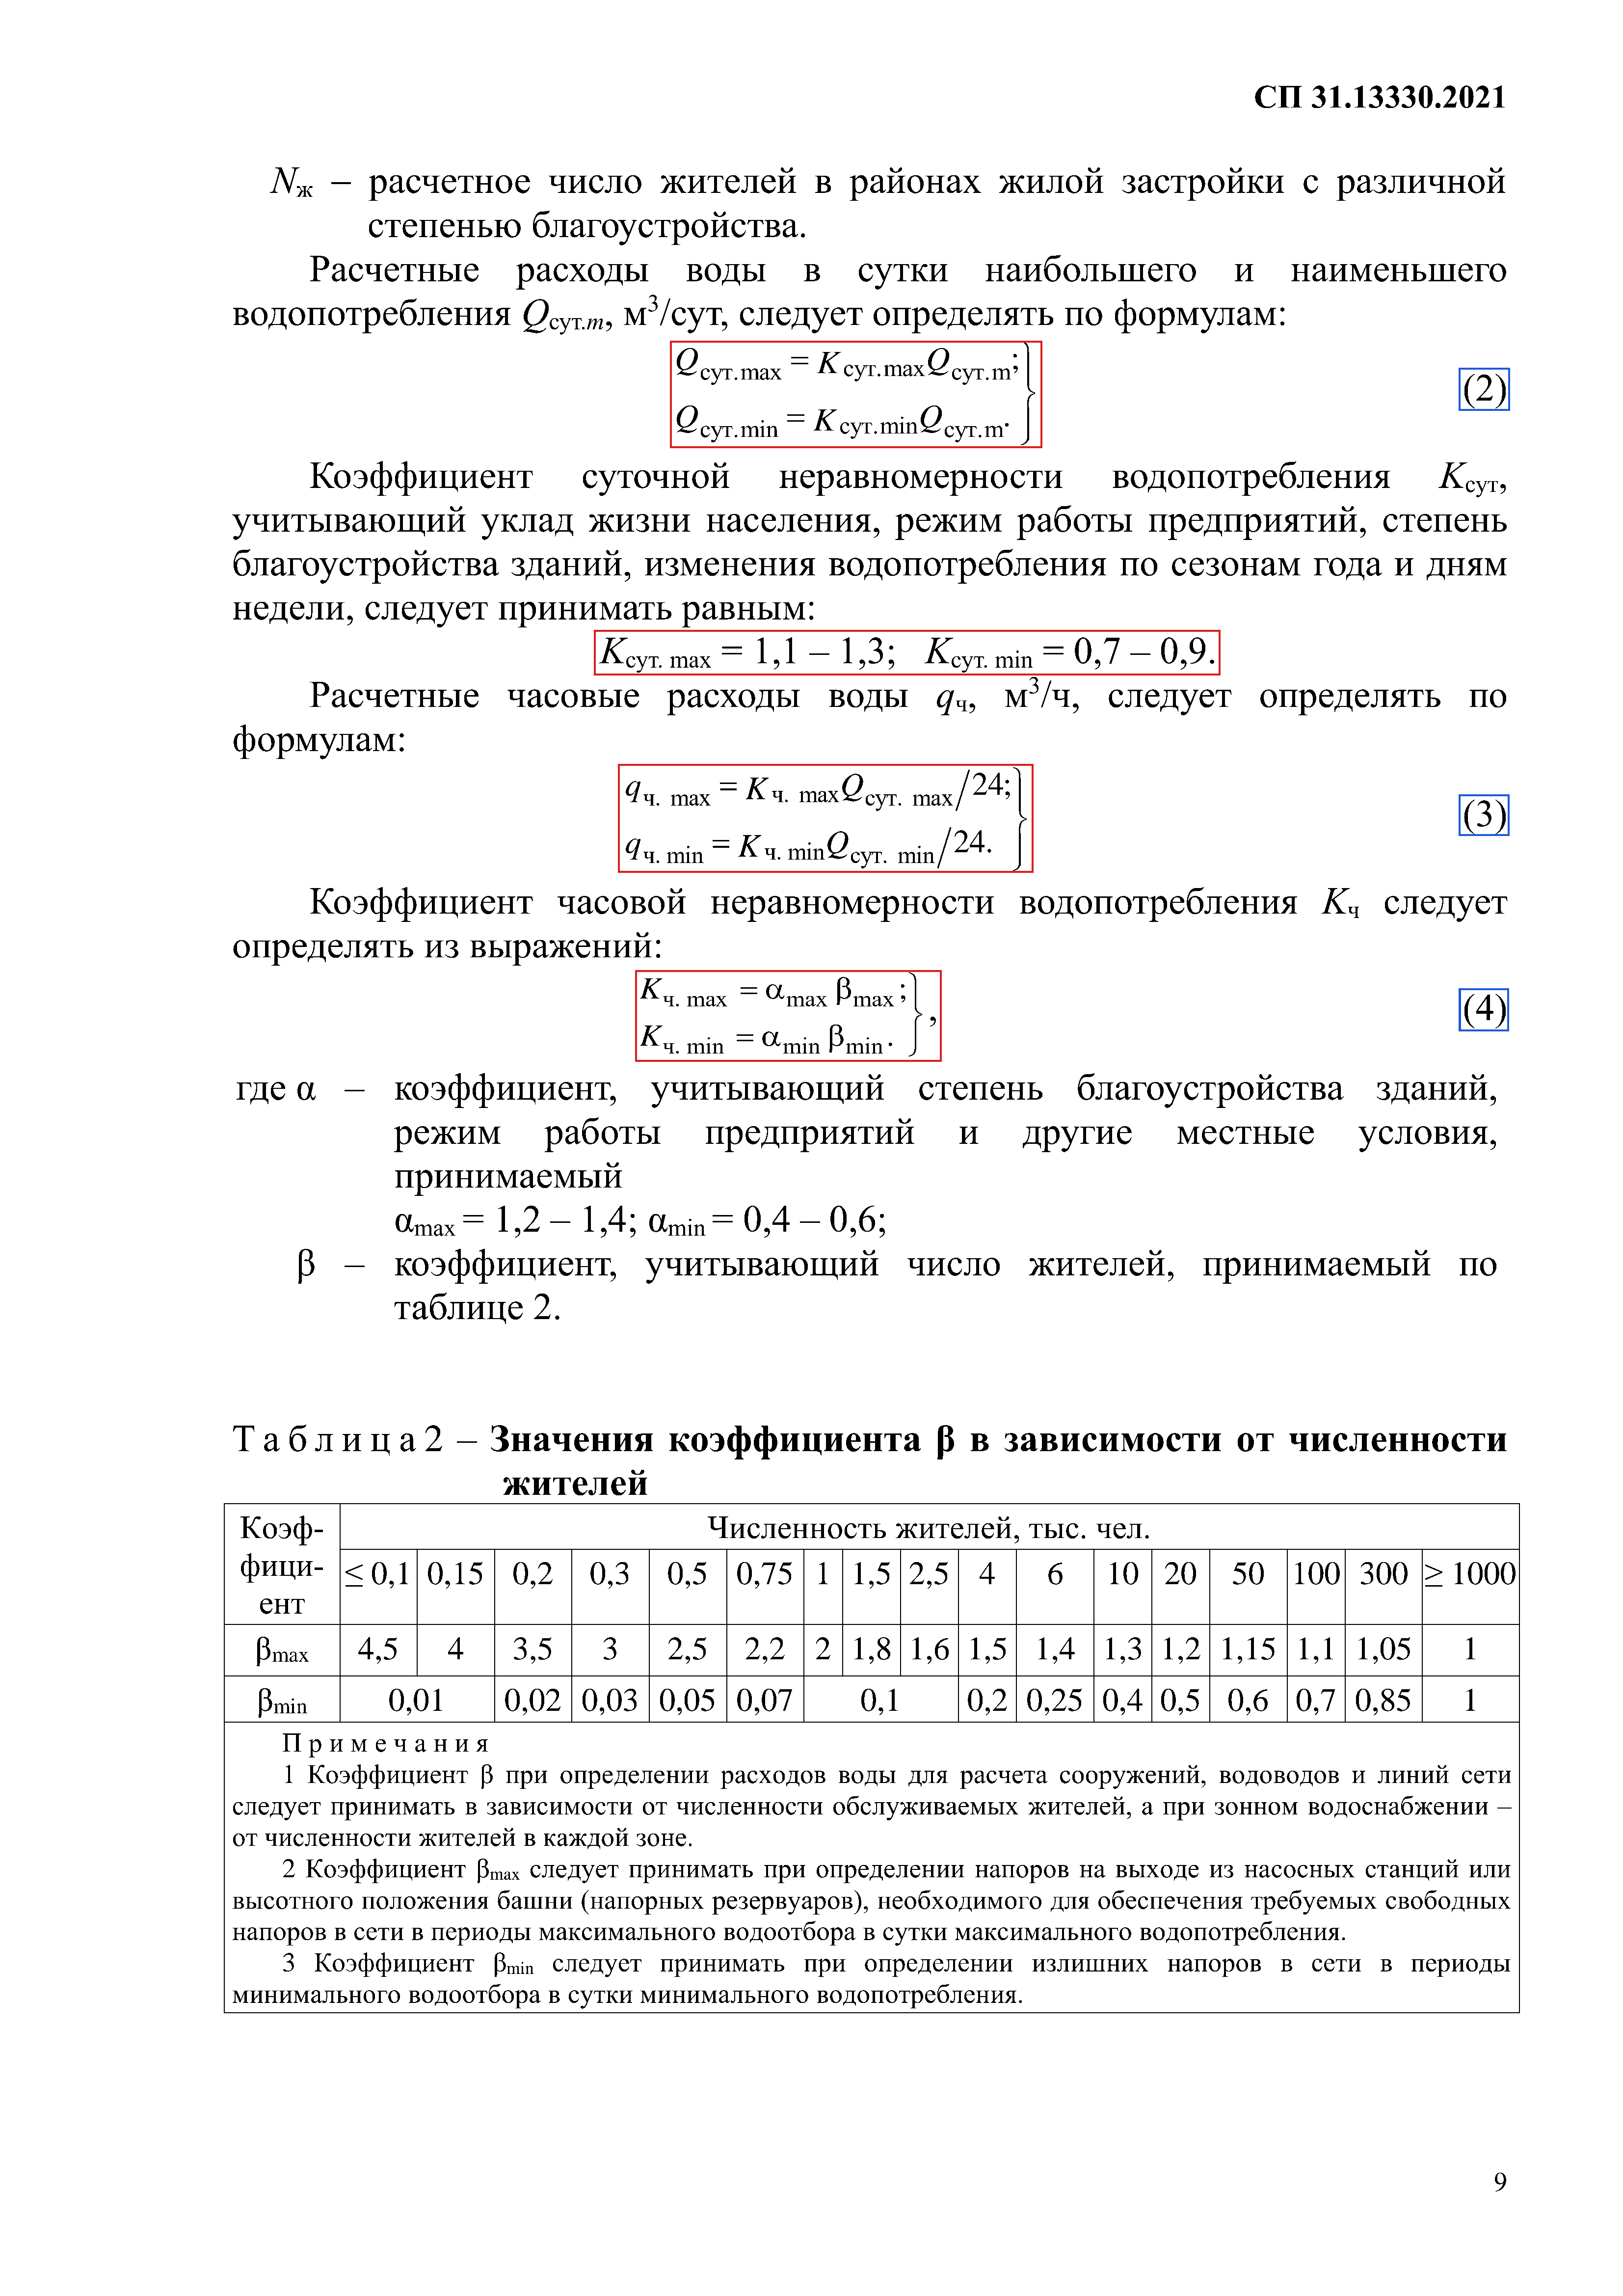

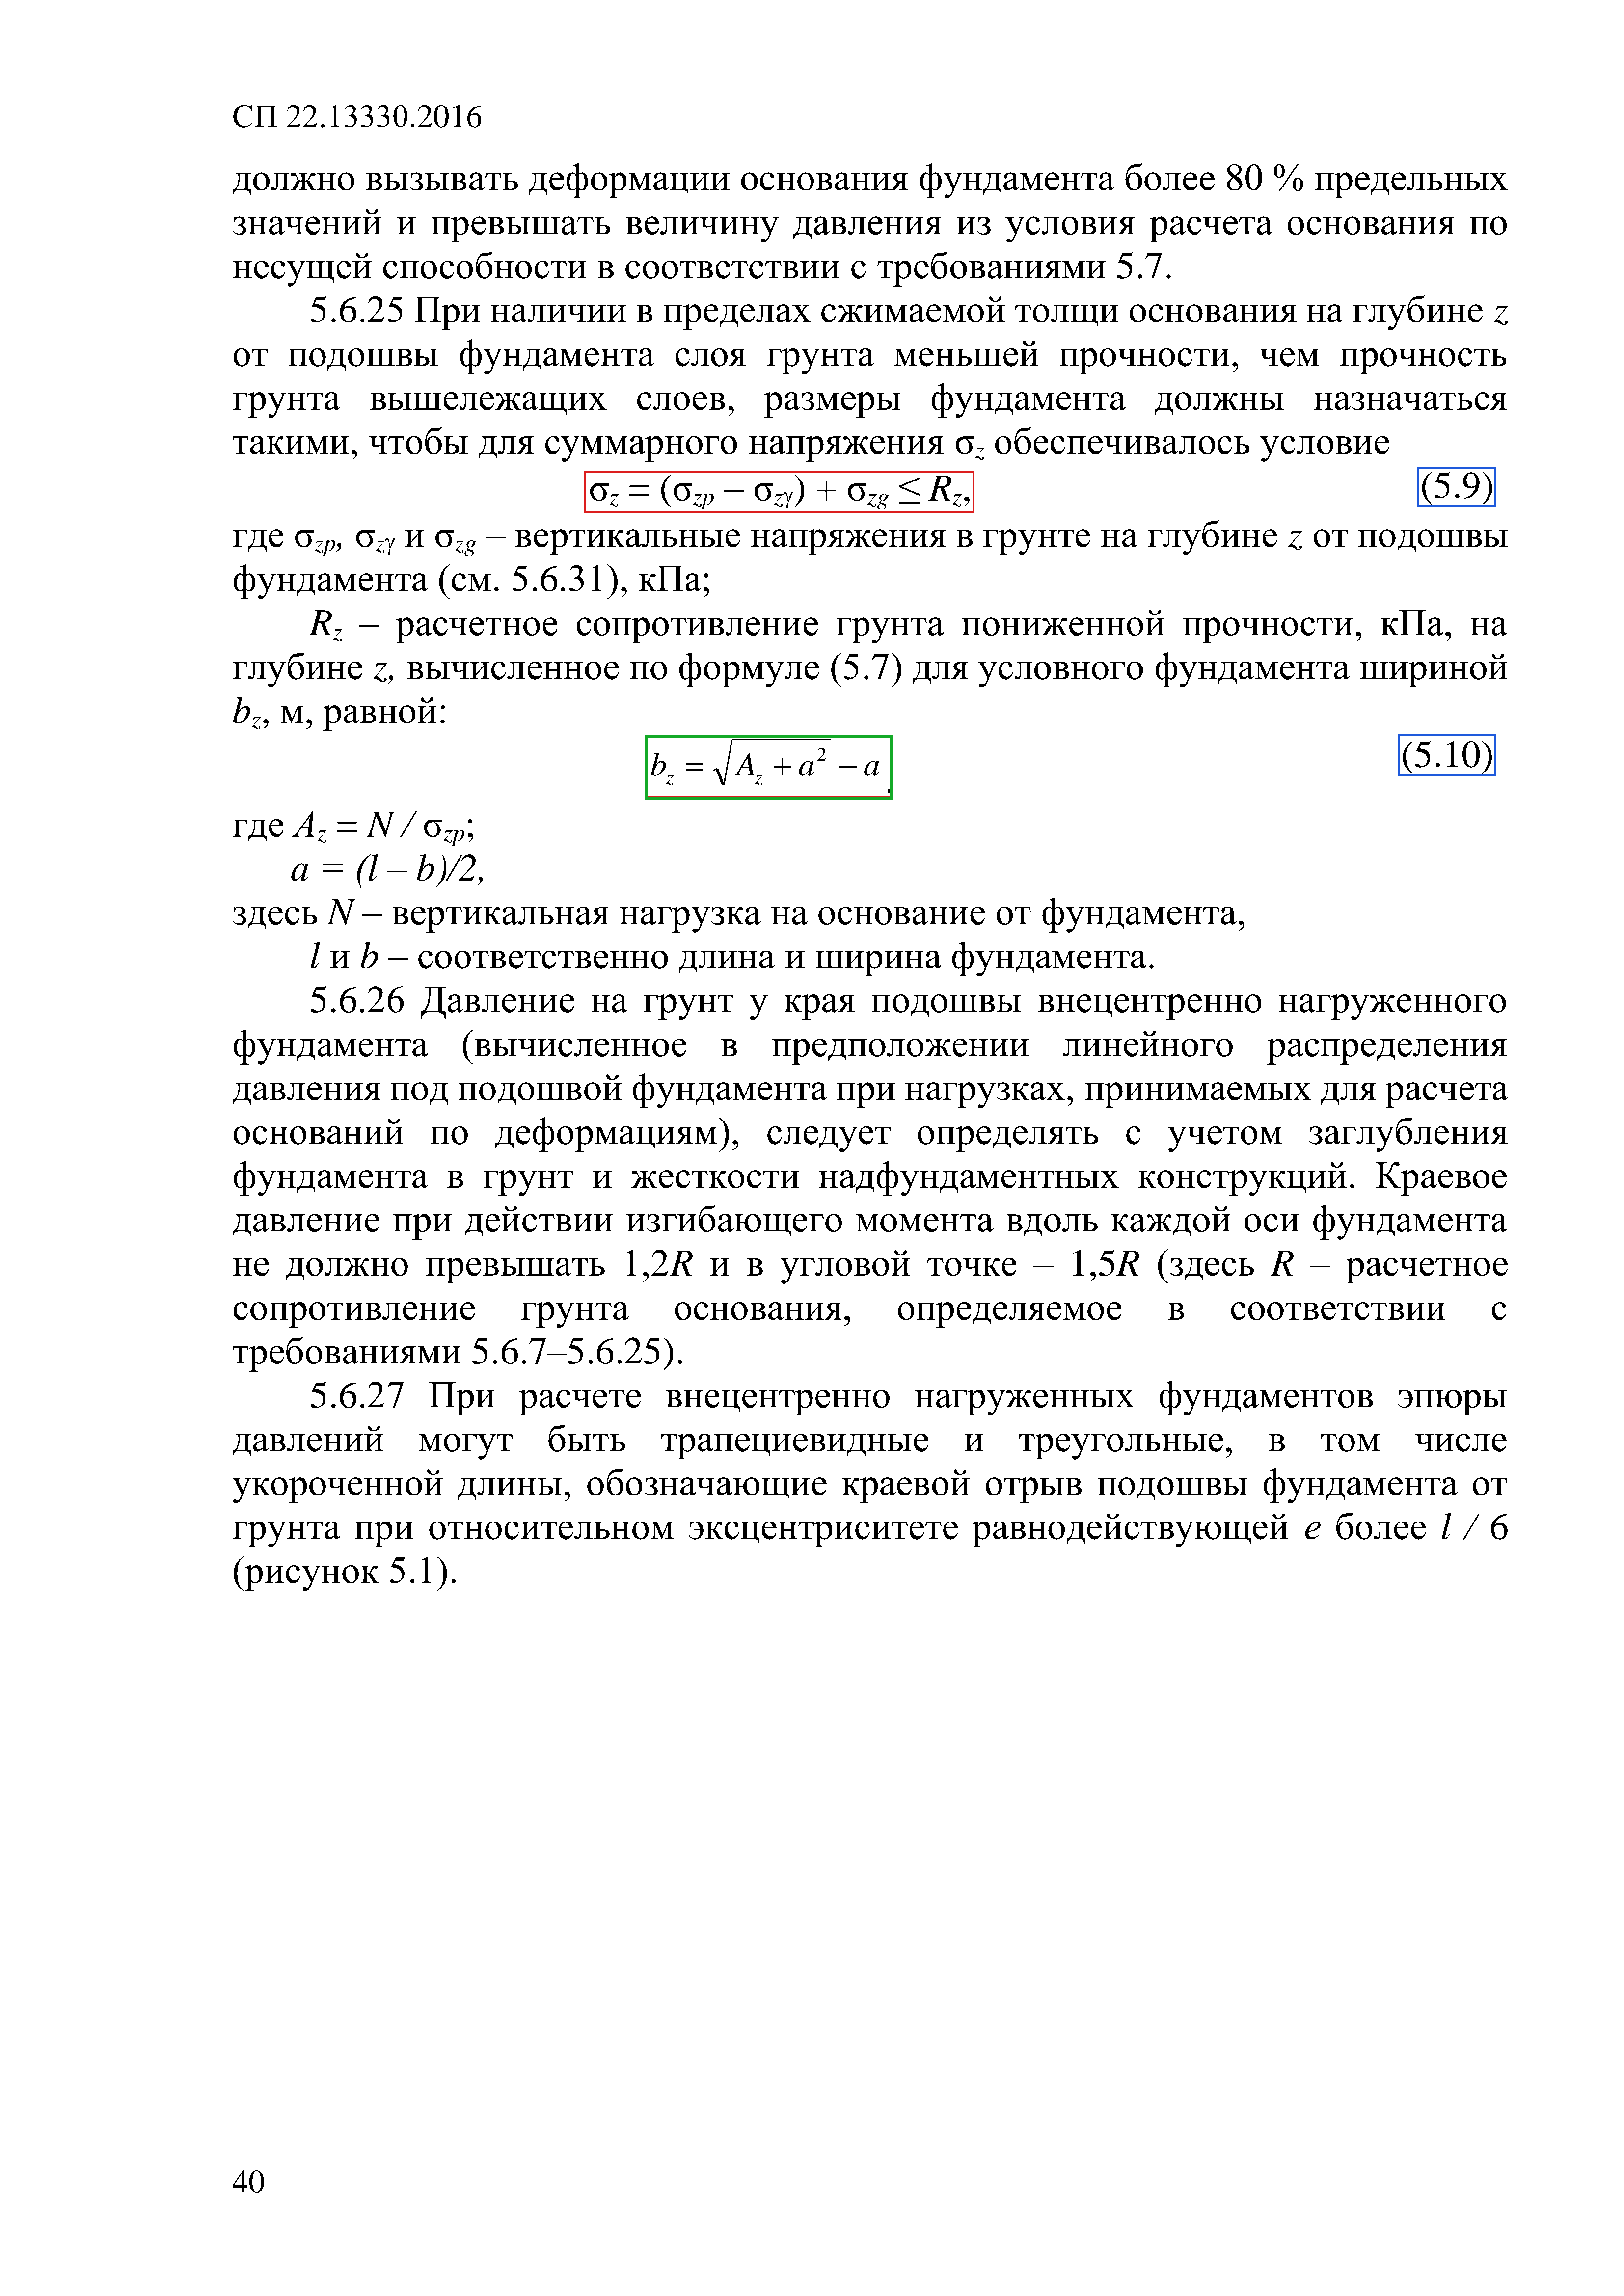

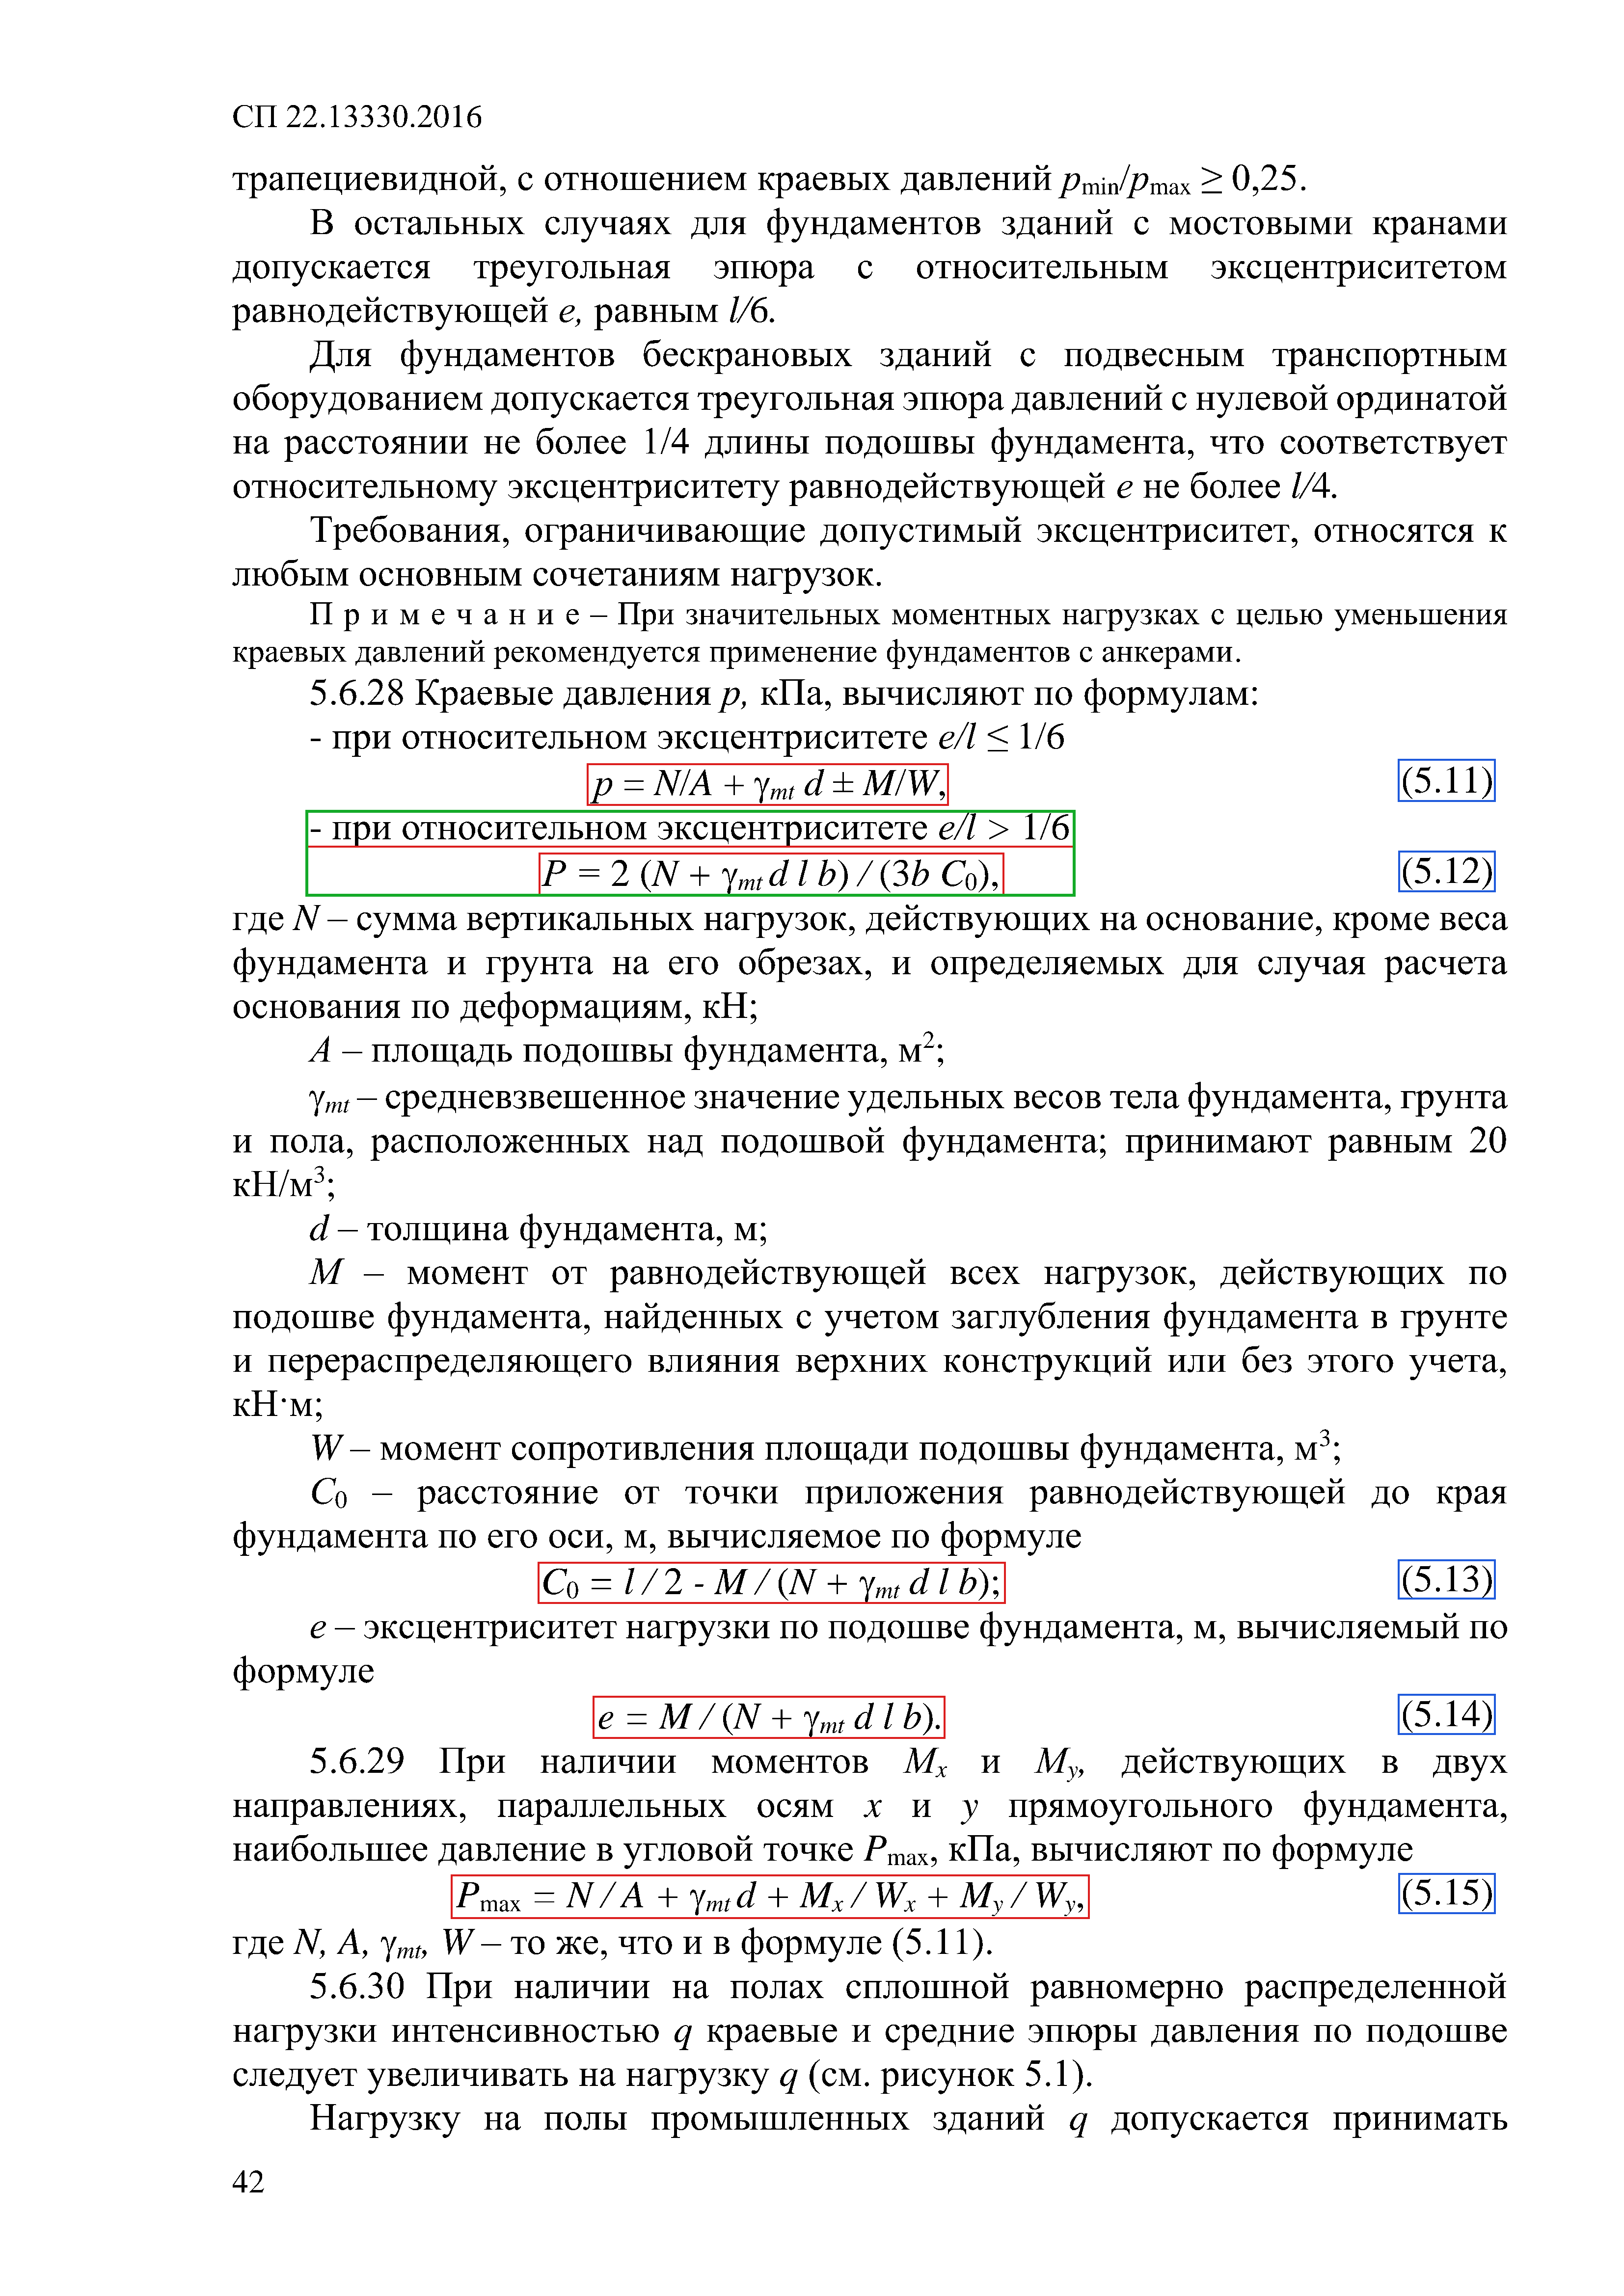

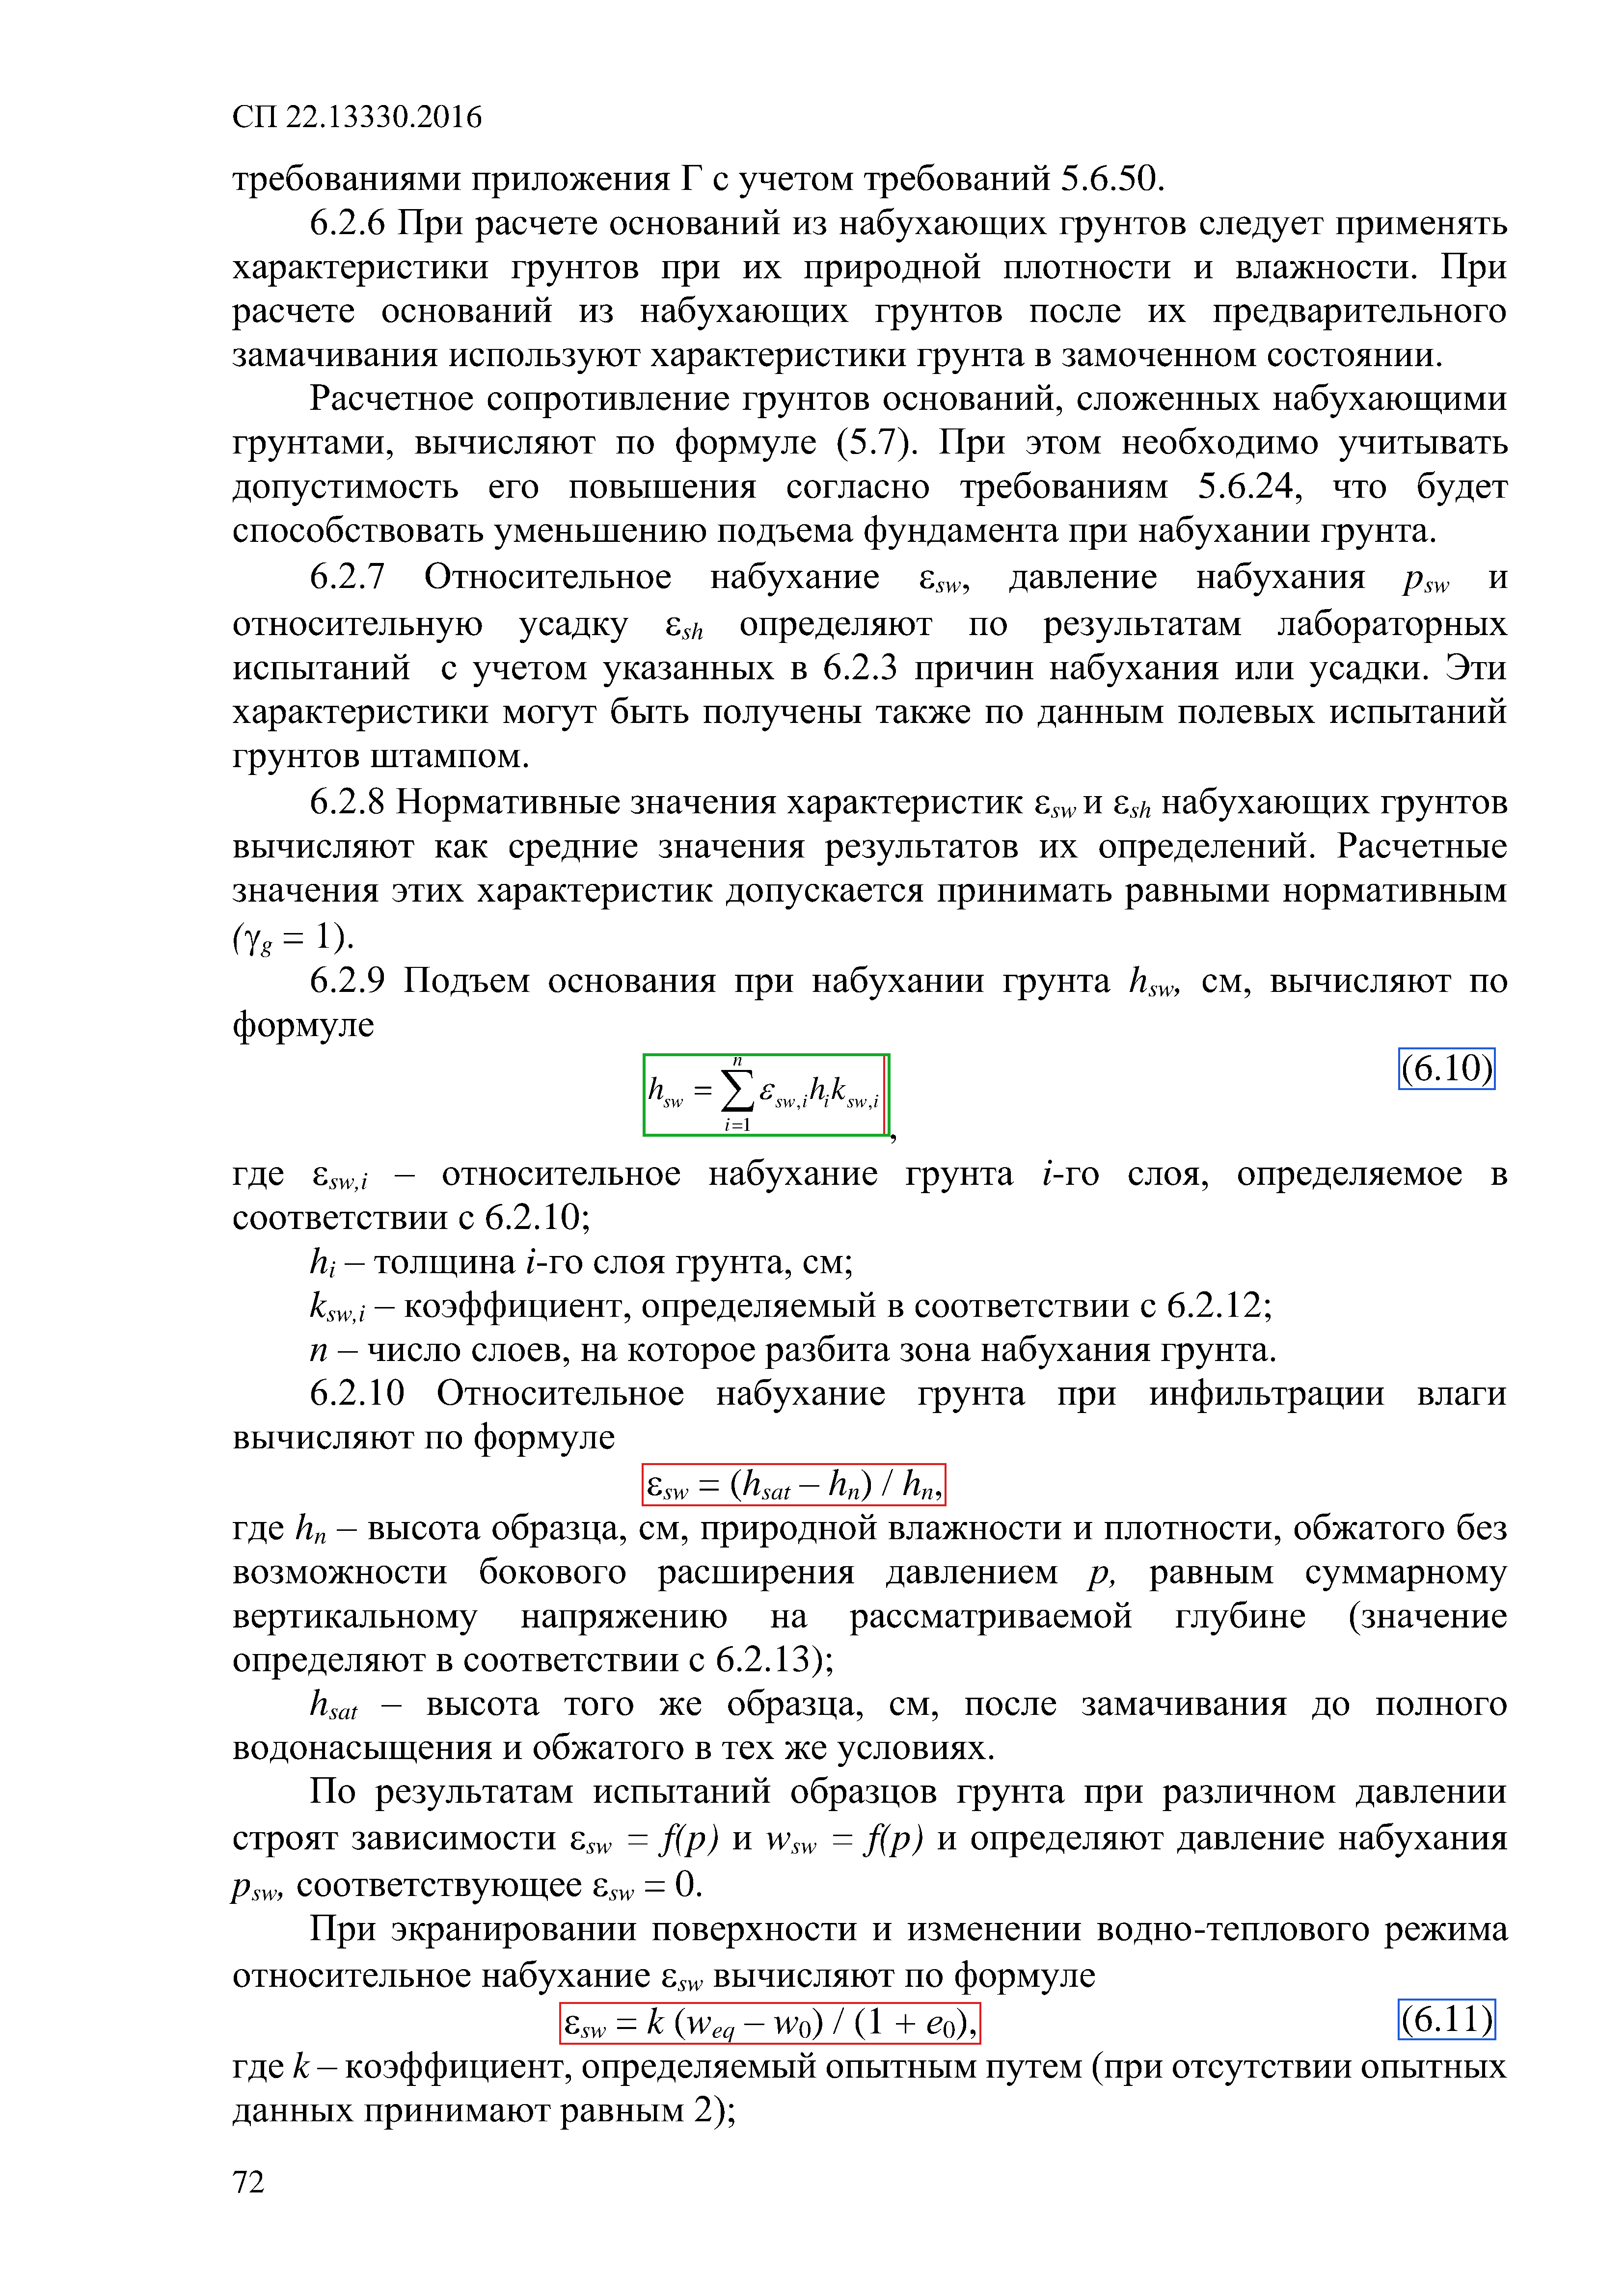

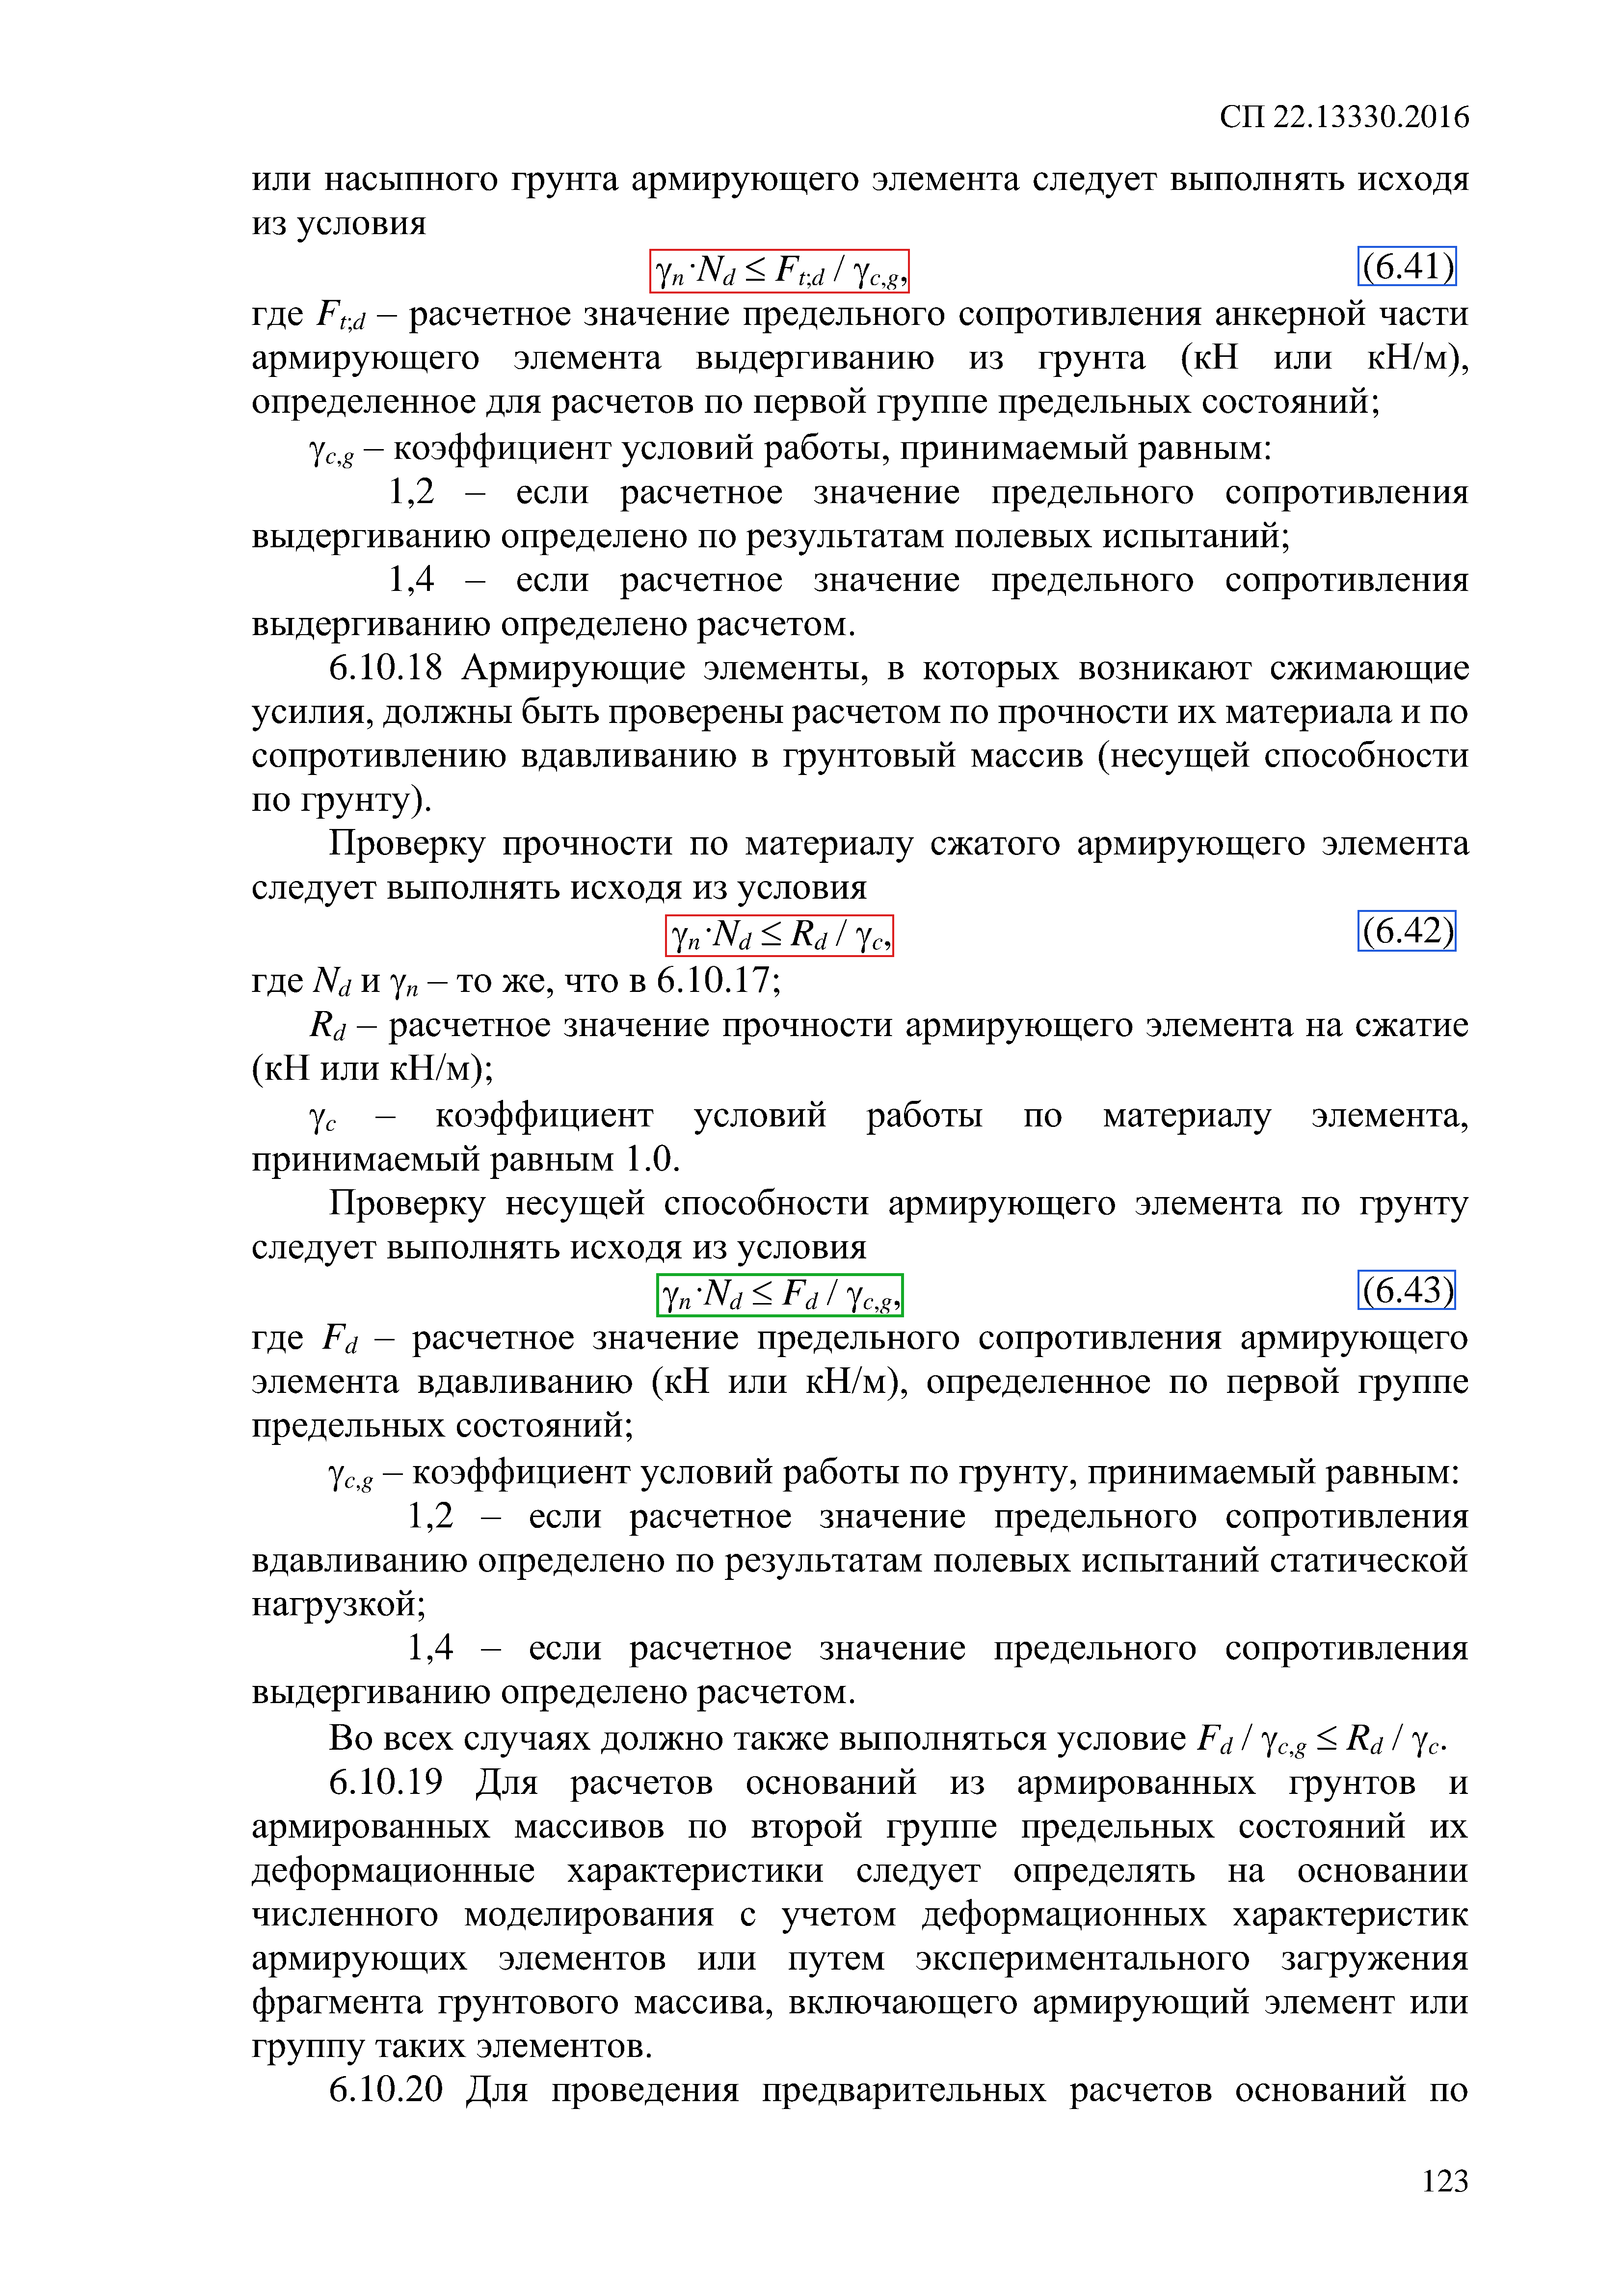

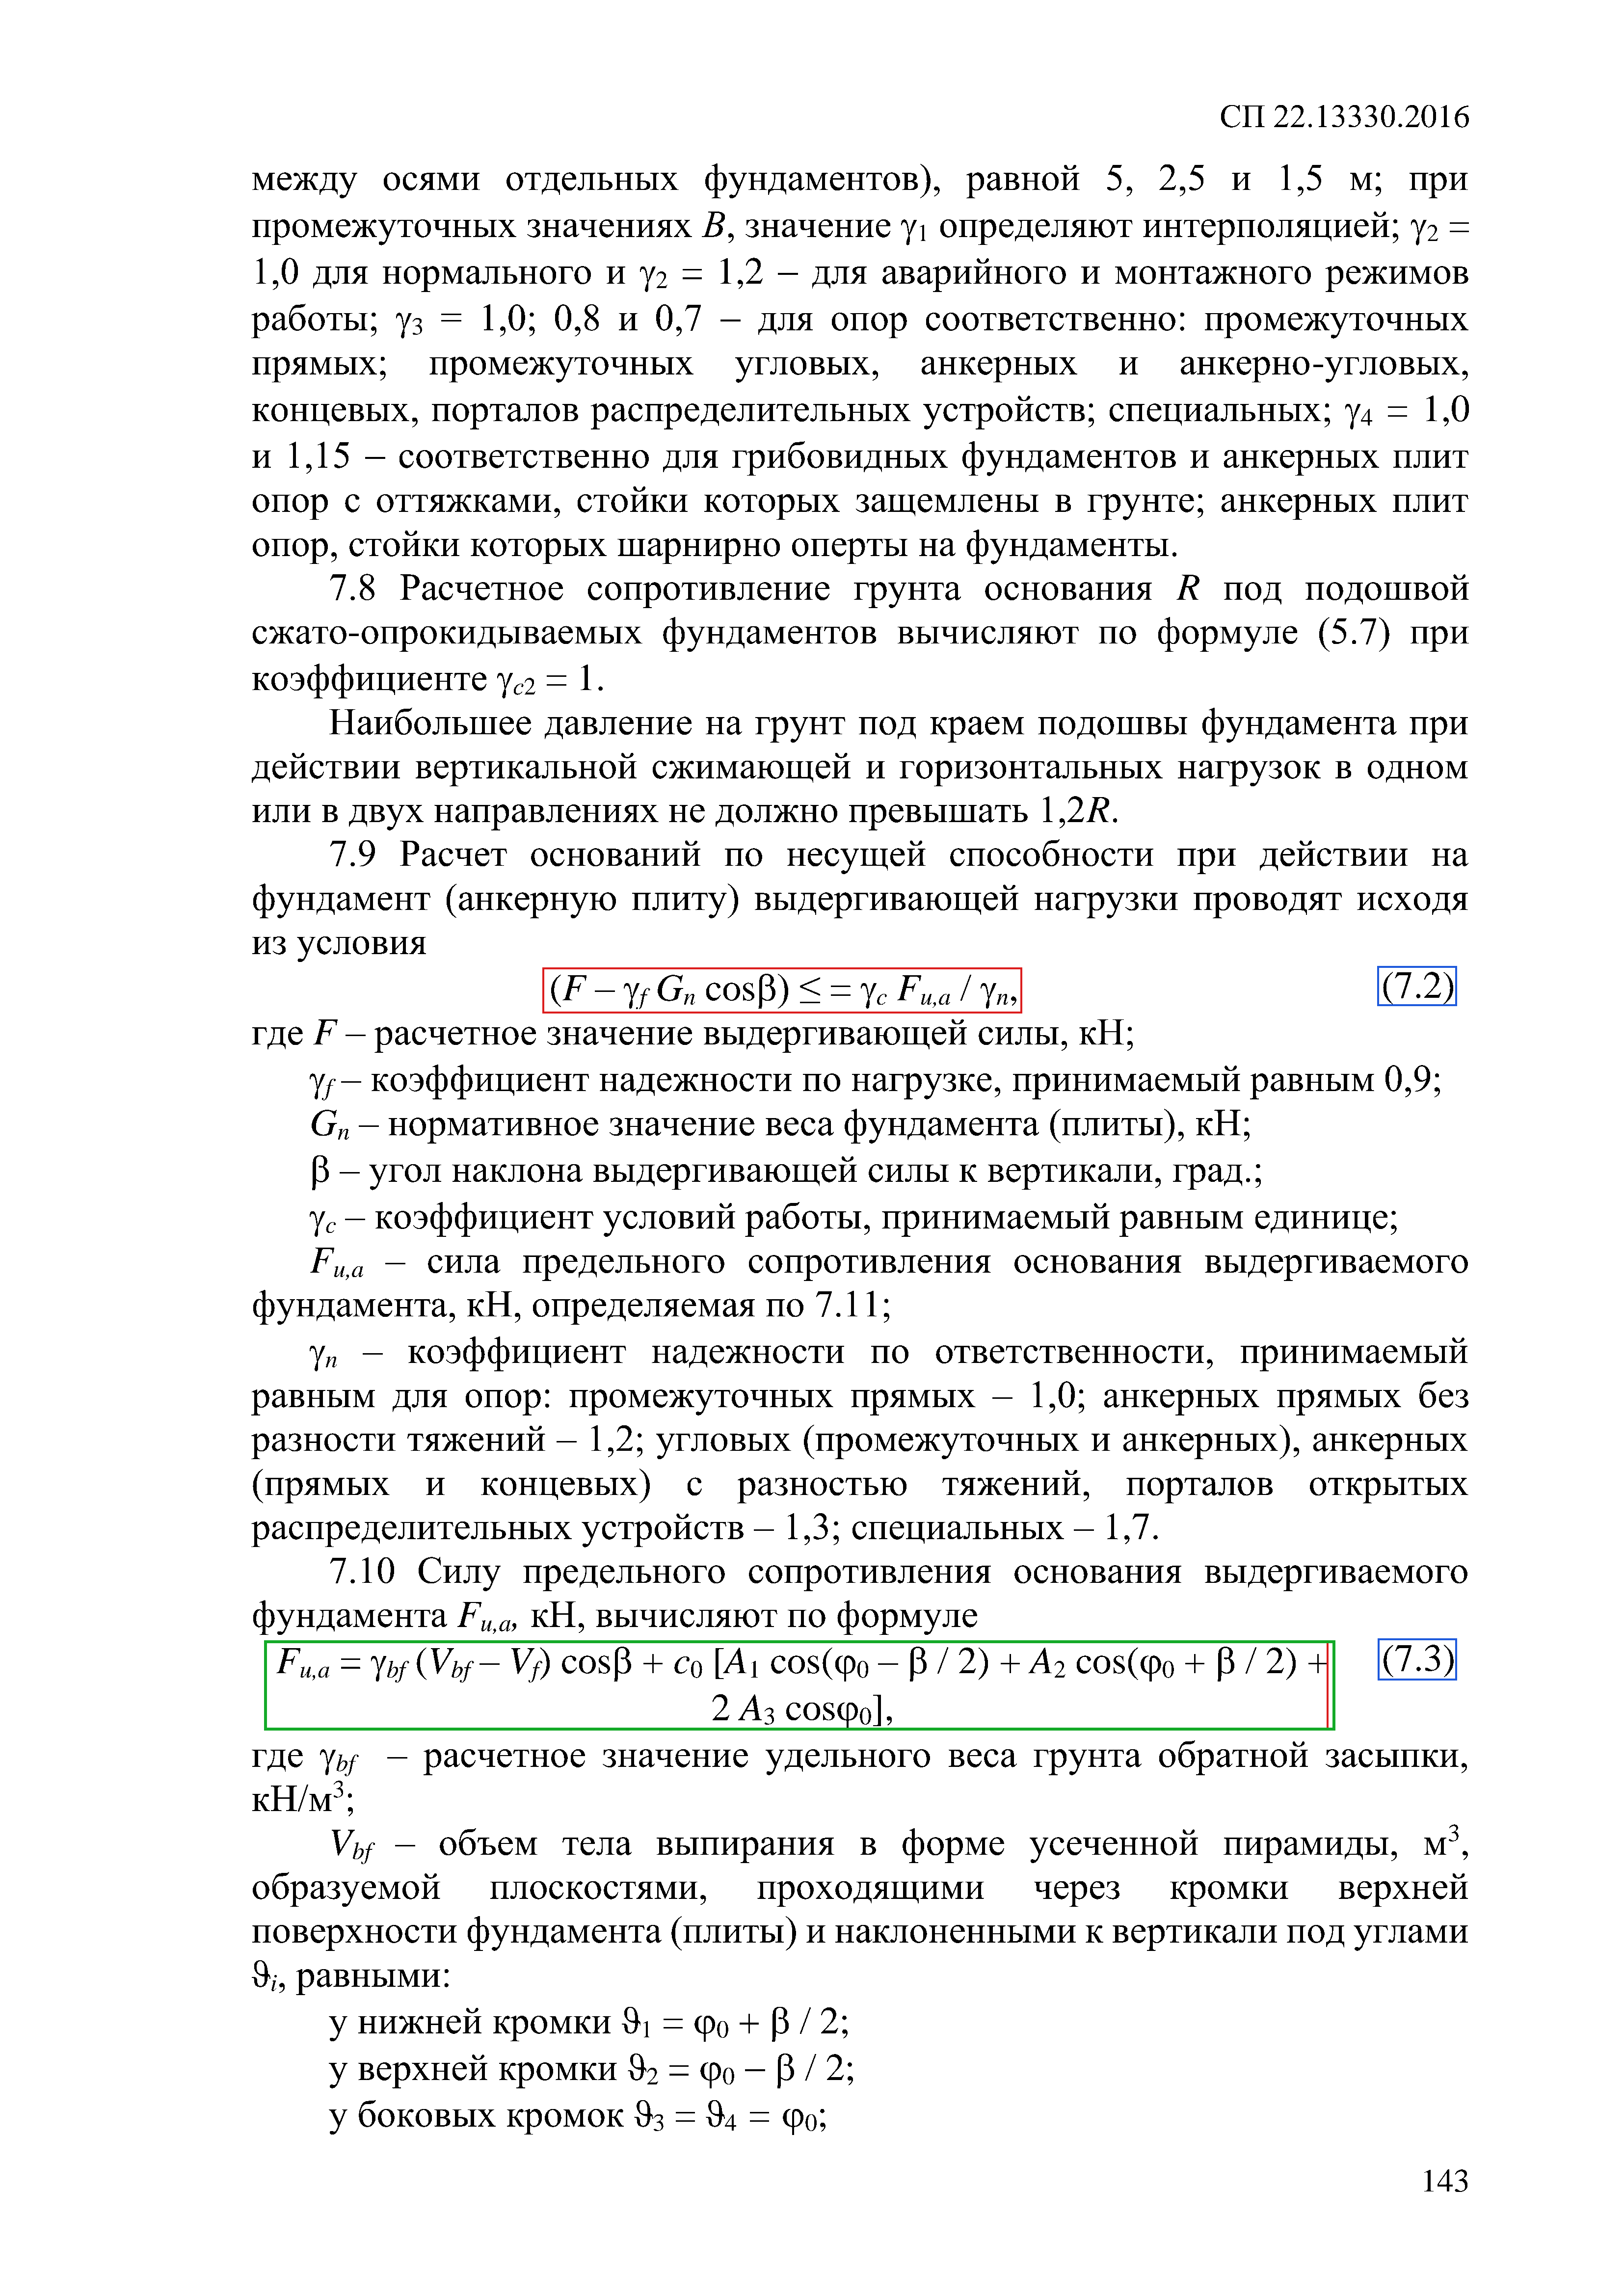

In [6]:
def viz(name, page_no, merged_boxes=()):
    with pdfplumber.open(DOCS[name]) as pdf:
        page = pdf.pages[page_no - 1]
        img = np.array(page.to_image(resolution=DPI).original)
    blocks = layout_blocks(img[..., ::-1])
    im = Image.fromarray(img).copy()
    d = ImageDraw.Draw(im)
    for b in blocks["isolate_formula"]:
        d.rectangle(b, outline=(220, 30, 30), width=4)
    for c in blocks["formula_caption"]:
        d.rectangle(c, outline=(30, 90, 220), width=4)
    for b in merged_boxes:
        d.rectangle(b, outline=(20, 170, 40), width=6)
    p = CROPS / f"nb08_{name}_boxes_p{page_no}.png"
    im.save(p)
    display(IPyImage(filename=str(p)))


viz("pilot", 13)
for (name, page, _number) in merged_ocr:
    g = [x for x in group_numbers(data[name]) if x["page"] == page and x["number"] == _number][0]
    viz(name, page, merged_boxes=[g["box"]])

## 5. Выводы

- Пилот СП 31: системы 2–4 — единым боксом (`\left.\begin{aligned}…\right\}`), объединение
  не нужно.
- Тест СП 22: дубли/разбиения (5.10, 5.12, 6.10, 6.43, 7.3) чинятся группировкой по номеру.
- Кириллица: текстовый слой даёт точные русские индексы, pix2text — латиницу вразрядку;
  финальный LaTeX берём из текстового слоя, структуру/границы — из DocLayout-YOLO.

## 6. PDF ↔ «БД»: HTML-рендер LaTeX рядом с формулой из PDF

Для 3–4 систем: слева кроп из PDF, справа HTML-рендер (MathJax) того же LaTeX, который
пойдёт в БД (кириллические индексы обёрнуты в `\text{}` для корректного отображения).

In [7]:
from IPython.display import HTML


def formula_box(name, page, number):
    items = [s for s in data[name] if s["page"] == page and s["number"] == number]
    b = [tuple(i["box"]) for i in items]
    return (min(x[0] for x in b), min(x[1] for x in b),
            max(x[2] for x in b), max(x[3] for x in b))


def save_pdf_crop(name, page, number, path):
    with pdfplumber.open(DOCS[name]) as pdf:
        img = np.array(pdf.pages[page - 1].to_image(resolution=DPI).original)
    b = formula_box(name, page, number)
    Image.fromarray(img[b[1]:b[3], b[0]:b[2]]).save(path)


def db_latex(name, page, number):
    with pdfplumber.open(DOCS[name]) as pdf:
        tex = reconstruct_latex(pdf.pages[page - 1], number) or ""
    return re.sub(r"[а-яёА-ЯЁ]+", lambda m: "\\text{" + m.group(0) + "}", tex)


COMPARE = [
    ("pilot ✓", 13, "2"),
    ("pilot ✓", 13, "4"),
    ("test ✓", 78, "6.10"),
    ("test ✓", 149, "7.3"),
]
for i, (tag, page, number) in enumerate(COMPARE):
    name = "pilot" if tag.startswith("pilot") else "test"
    png = CROPS / f"nb08_cmp_{i}.png"
    save_pdf_crop(name, page, number, png)
    tex = db_latex(name, page, number)
    display(HTML(
        f'<div style="display:flex;gap:24px;align-items:center;margin:10px 0">'
        f'<img src="crops/nb08_cmp_{i}.png" style="height:120px;border:1px solid #ccc">'
        f'<div style="font-size:18px">$${tex}$$</div></div>'
    ))
    print(f"{tag} p{page} ({number})")

pilot ✓ p13 (2)


pilot ✓ p13 (4)


test ✓ p78 (6.10)


test ✓ p149 (7.3)


## 7. Условия применимости формулы («- при относительном эксцентриситете…») — не терять

Перед формулой стоит строка-условие; детектор иногда принимает её за `isolate_formula`.
Условие берём из текстового слоя: строка перед строкой с `(N)`, начинающаяся с `-`.

In [8]:
from normatives_pipeline.parser import text_layer

_TEXT = {name: text_layer.read_pages(path) for name, path in DOCS.items()}


def condition_for(name, page_no, number):
    lines = _TEXT[name][page_no - 1].splitlines()
    idx = next((i for i, l in enumerate(lines) if f"({number})" in l), None)
    if idx is None:
        return ""
    j = idx - 1
    while j >= 0 and not lines[j].strip():
        j -= 1
    if j < 0:
        return ""
    cand = lines[j].strip()
    if cand[0] in "-–—" or "при " in cand:
        return cand.lstrip("-–— ").strip()
    return ""


for name, page, number in [("test", 48, "5.11"), ("test", 48, "5.12")]:
    print(f"({number}) p{page}")
    print(f"  условие: {condition_for(name, page, number)}")
    print(f"  формула: {db_latex(name, page, number)}")

print()
for name in DOCS:
    uniq = {(x["page"], x["number"]) for x in data[name]}
    with_cond = [k for k in uniq if condition_for(name, *k)]
    print(f"{name}: с условием «- при …» {len(with_cond)}/{len(uniq)}")

(5.11) p48
  условие: при относительном эксцентриситете е/l ≤ 1/6


  формула: \text{р}=N/A+\gamma_{mt}d±M/W,
(5.12) p48
  условие: при относительном эксцентриситете е/l > 1/6


  формула: \text{Р}=2(N+\gamma_{mt}dlb)/(3bC_{0}),

pilot: с условием «- при …» 2/13
test: с условием «- при …» 6/122


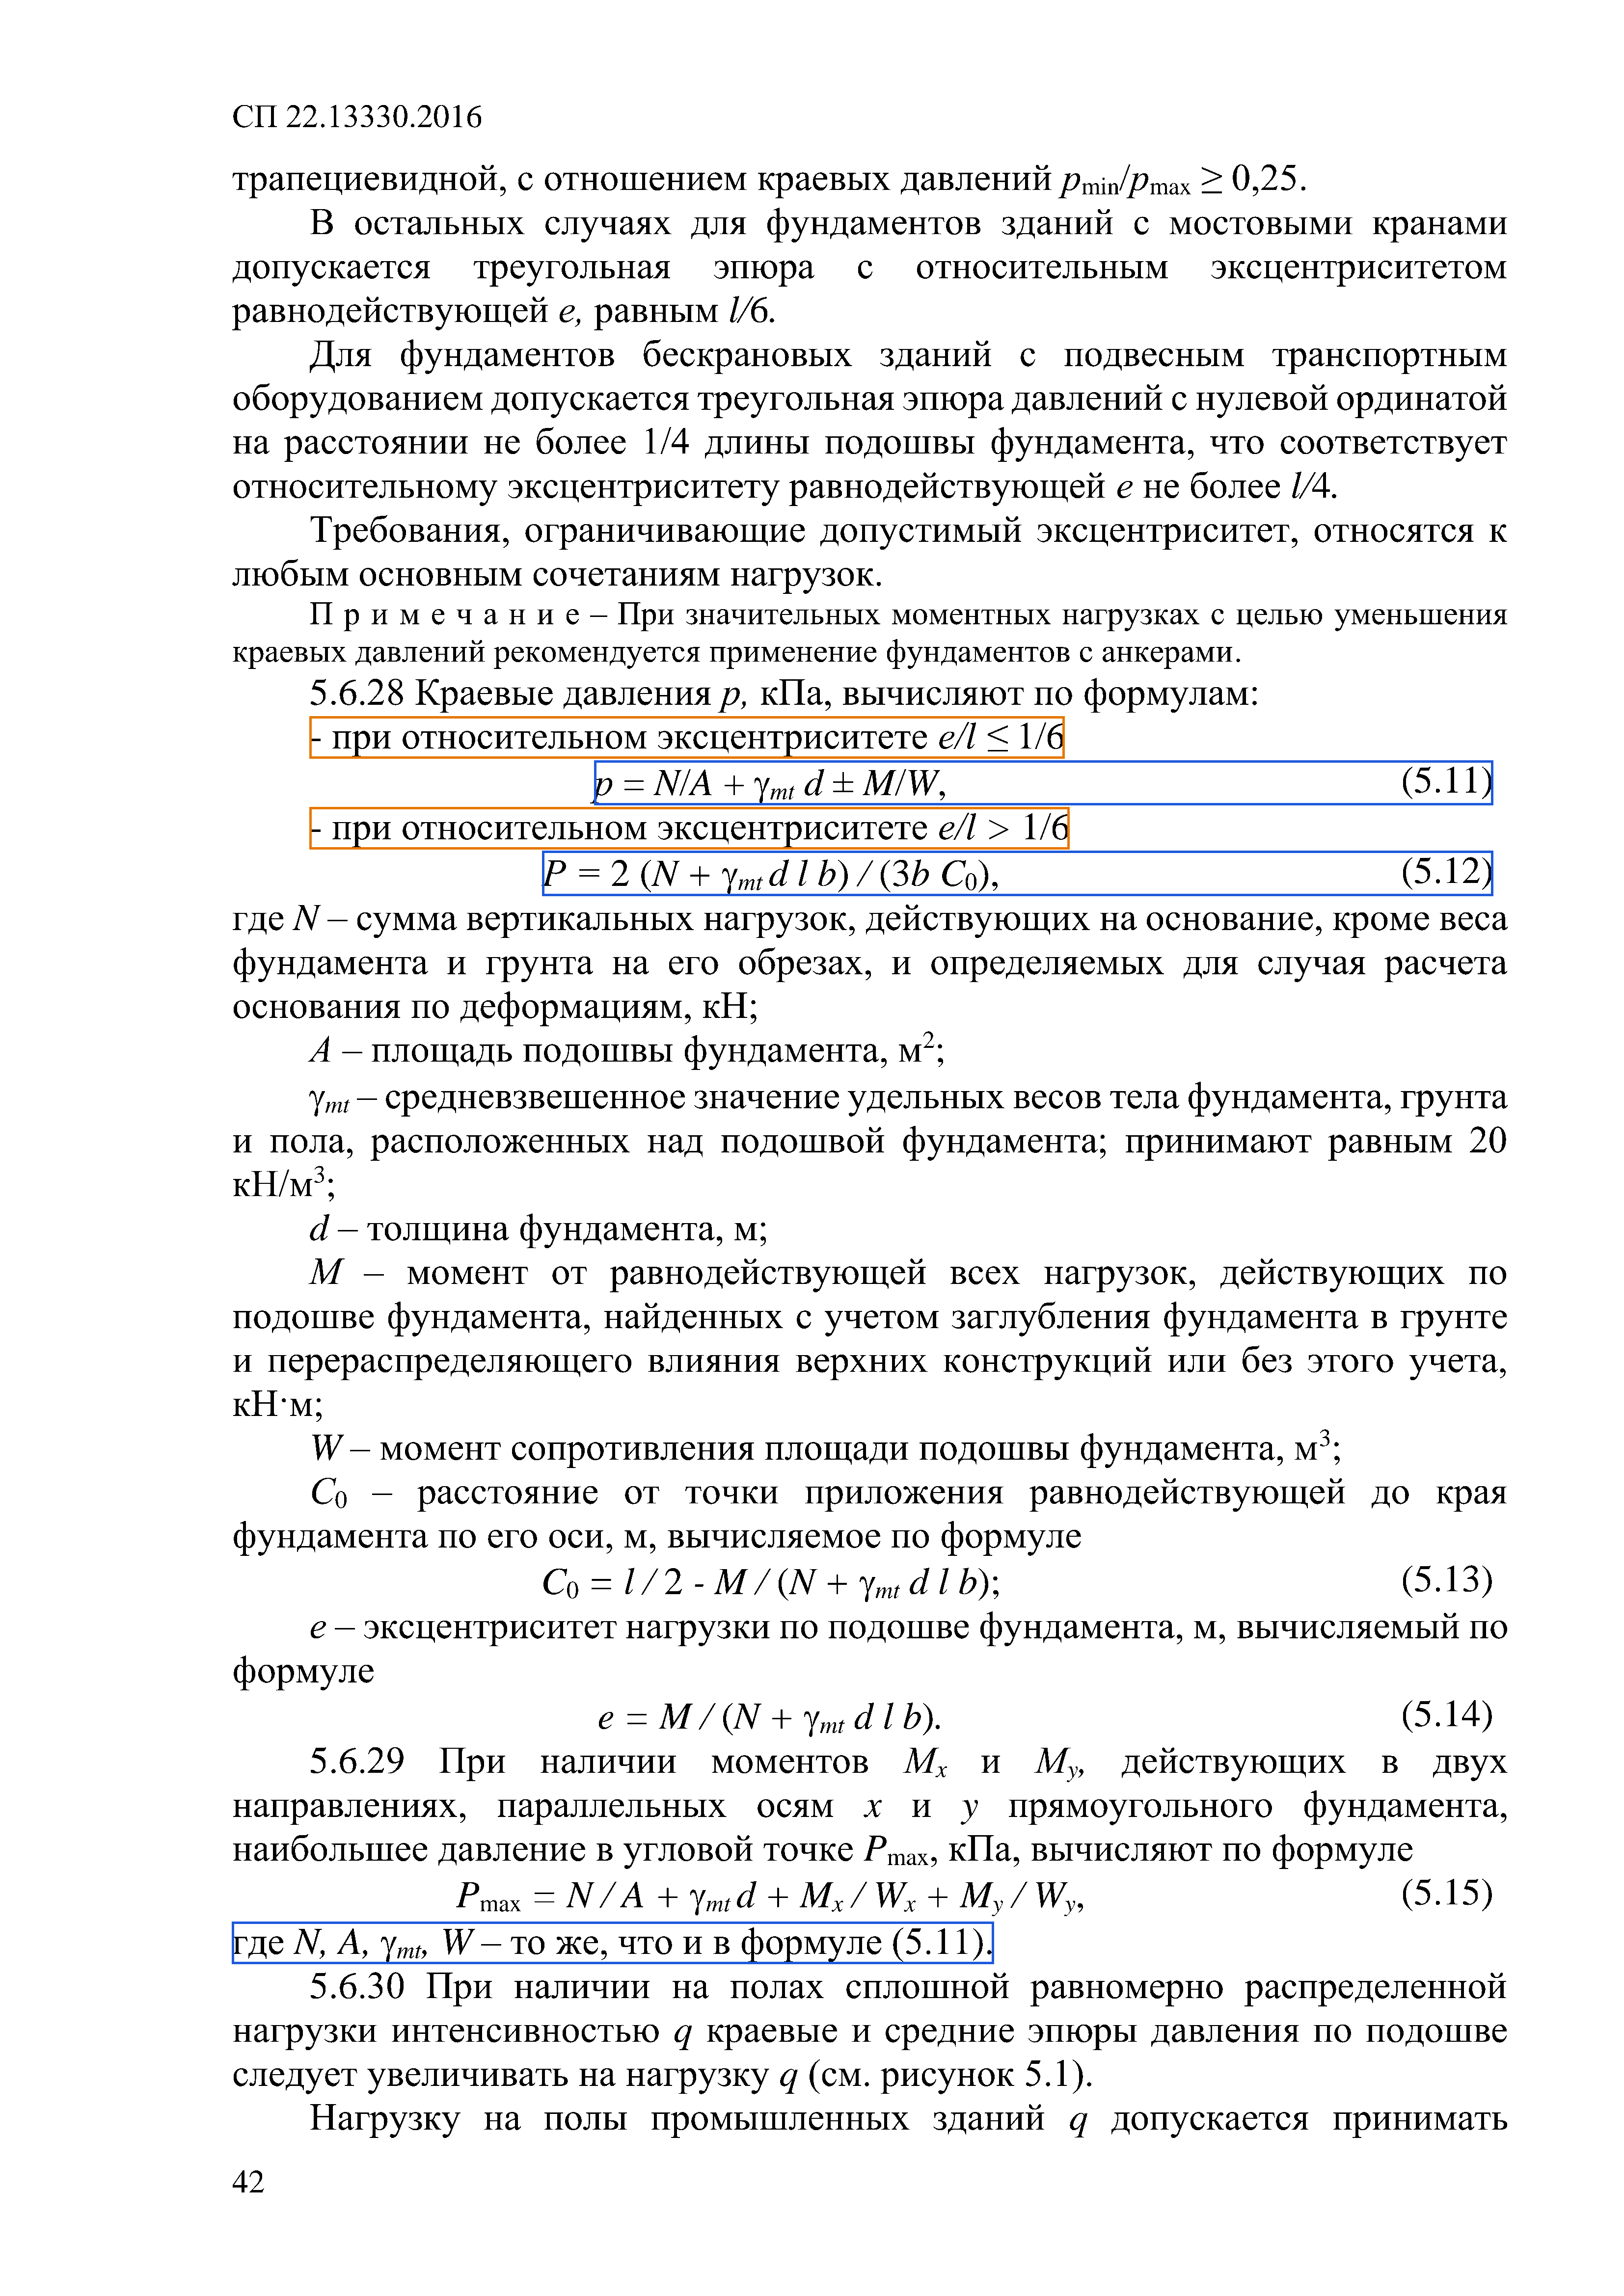

оранжевый = условие «- при …», синий = номер формулы


In [9]:
with pdfplumber.open(DOCS["test"]) as pdf:
    const_page = pdf.pages[47]
    img = np.array(const_page.to_image(resolution=DPI).original)
    txt_lines = const_page.extract_text_lines()
im = Image.fromarray(img).copy()
d = ImageDraw.Draw(im)
for ln in txt_lines:
    box = (int(ln["x0"] * SCALE), int(ln["top"] * SCALE) - 4,
           int(ln["x1"] * SCALE), int(ln["bottom"] * SCALE) + 4)
    if "при относительном" in ln["text"]:
        d.rectangle(box, outline=(230, 120, 0), width=5)
    if "(5.11)" in ln["text"] or "(5.12)" in ln["text"]:
        d.rectangle(box, outline=(30, 90, 220), width=5)
p = CROPS / "nb08_p48_conditions.png"
im.save(p)
display(IPyImage(filename=str(p)))
print("оранжевый = условие «- при …», синий = номер формулы")
for name, page, number in [("test", 48, "5.11"), ("test", 48, "5.12")]:
    cond = condition_for(name, page, number)
    tex = db_latex(name, page, number)
    display(HTML(
        f'<div style="margin:8px 0;font-size:17px">'
        f'<b>({number})</b> условие: {cond}<br>'
        f'формула: $${tex}$$</div>'
    ))

## 8. Финальный модуль: лучшие решения (с docstring)

Собираем проверенные решения в один набор функций: DocLayout-YOLO (боксы/подписи) →
привязка бокс↔подпись `(N)` → группировка по номеру → LaTeX из текстового слоя (точная
кириллица, индексы, дроби, системы) → условие применимости.

In [10]:
def find_markers(chars):
    """Все номера формул «(N)»/«(N.M)» на странице: [(number, top, x открывающей скобки)]."""
    out = []
    for row in _cluster([c for c in chars if c["text"].strip()], 1.5):
        rc = sorted(row["chars"], key=lambda c: c["x0"])
        text = "".join(c["text"] for c in rc)
        for m in re.finditer(r"\((\d{1,2}(?:\.\d+)?)\)", text):
            acc = 0
            for c in rc:
                if acc == m.start():
                    out.append((m.group(1), row["top"], c["x0"]))
                    break
                acc += len(c["text"])
    return out


def detect_layout(page, img):
    """Боксы DocLayout-YOLO на странице (400 dpi): isolate_formula и formula_caption."""
    return layout_blocks(img[..., ::-1])


def caption_number(page, bbox):
    """Номер формулы «(N)» из текста подписи справа от бокса."""
    x0, y0, x1, y1 = (v / SCALE for v in bbox)
    txt = re.sub(r"\s+", "", page.crop((x0, y0, x1, y1)).extract_text() or "")
    m = re.search(r"\((\d+(?:\.\d+)?)\)", txt)
    return m.group(1) if m else ""


def pair_formulas(page, blocks):
    """Бокс ↔ подпись: подпись справа с вертикальным перекрытием; ближайшая по вертикали."""
    pairs, used_box, used_cap = [], set(), set()
    captions = blocks["formula_caption"]
    for b in sorted(blocks["isolate_formula"], key=lambda b: b[1]):
        best = None
        for ci, c in enumerate(captions):
            if c[0] >= b[2] - 8 and c[1] < b[3] + 12 and b[1] - 12 < c[3]:
                dist = abs((c[1] + c[3]) / 2 - (b[1] + b[3]) / 2)
                if best is None or dist < best[0]:
                    best = (dist, ci)
        if best is not None:
            pairs.append((tuple(b), captions[best[1]]))
            used_box.add(id(b))
            used_cap.add(best[1])
    return pairs, [b for b in blocks["isolate_formula"] if id(b) not in used_box], \
        [c for i, c in enumerate(captions) if i not in used_cap]


def union_box(boxes):
    """Объединяющий бокс: чинит системы, разбитые/дублированные детектором на несколько боксов."""
    return (min(b[0] for b in boxes), min(b[1] for b in boxes),
            max(b[2] for b in boxes), max(b[3] for b in boxes))


def formula_latex(page, number):
    """LaTeX формулы из текстового слоя: точная кириллица, индексы, дроби, системы."""
    return reconstruct_latex(page, number)


def formula_condition(pages_text, page_no, number):
    """Условие применимости «- при …»: строка перед строкой с номером формулы."""
    lines = pages_text[page_no - 1].splitlines()
    idx = next((i for i, l in enumerate(lines) if f"({number})" in l), None)
    if idx is None:
        return ""
    j = idx - 1
    while j >= 0 and not lines[j].strip():
        j -= 1
    if j < 0:
        return ""
    cand = lines[j].strip()
    if cand[0] in "-–—" or "при " in cand:
        return cand.lstrip("-–— ").strip()
    return ""


def extract_document(path, cache=None):
    """Полный проход: DocLayout боксы → привязка к (N) → LaTeX текстового слоя → условия.

    Возвращает список записей по каждой формуле: page, number, box, n_boxes, latex,
    condition, system, cyrillic. Кэшируется в JSON (повторный прогон мгновенный).
    """
    if cache is not None and cache.exists():
        return json.loads(cache.read_text())
    pages_text = text_layer.read_pages(path)
    grouped = {}
    with pdfplumber.open(path) as pdf:
        for pno, page in enumerate(pdf.pages, 1):
            if not find_markers(page.chars):
                continue
            img = np.array(page.to_image(resolution=DPI).original)
            pairs, _, _ = pair_formulas(page, detect_layout(page, img))
            for b, c in pairs:
                num = caption_number(page, c)
                if num:
                    grouped.setdefault((pno, num), []).append(b)
    out = []
    with pdfplumber.open(path) as pdf:
        for (pno, num), boxes in sorted(grouped.items()):
            latex = formula_latex(pdf.pages[pno - 1], num)
            out.append({
                "page": pno, "number": num, "box": union_box(boxes), "n_boxes": len(boxes),
                "latex": latex, "condition": formula_condition(pages_text, pno, num),
                "system": bool(latex) and "aligned" in latex,
                "cyrillic": bool(latex) and any("\u0400" <= ch <= "\u04ff" for ch in latex),
            })
    if cache is not None:
        cache.write_text(json.dumps(out, ensure_ascii=False, indent=1))
    return out

## 9. Прогон на невиданном СП (СП 24.13330.2021) + сравнения «БД ↔ PDF»

Документ не участвовал ни в подборе порогов, ни в отладке — проверка обобщаемости.

In [11]:
UNSEEN = ROOT / "docs" / "normative-base" / "СП 24.13330.2021.pdf"
CACHE = CROPS / "nb08_unseen_records.json"
records = extract_document(UNSEEN, cache=CACHE)
print(f"СП 24: номеров {len(records)}; с LaTeX {sum(bool(r['latex']) for r in records)}; "
      f"систем {sum(r['system'] for r in records)}; кириллица {sum(r['cyrillic'] for r in records)}; "
      f"условий {sum(bool(r['condition']) for r in records)}")


def save_crop(path, page_no, box, out):
    """Сохраняет кроп формулы из PDF по боксу (400 dpi)."""
    with pdfplumber.open(path) as pdf:
        img = np.array(pdf.pages[page_no - 1].to_image(resolution=DPI).original)
    Image.fromarray(img[box[1]:box[3], box[0]:box[2]]).save(out)


def for_html(tex):
    """LaTeX → HTML-вид: кириллица в \\text{} и текстовое отображение для MathJax."""
    return re.sub(r"[а-яёА-ЯЁ]+", lambda m: "\\text{" + m.group(0) + "}", tex or "")


picks = sorted(records, key=lambda r: (not r["system"], not r["cyrillic"], r["page"], r["number"]))[:4]
for i, r in enumerate(picks):
    png = CROPS / f"nb08_unseen_{i}.png"
    save_crop(UNSEEN, r["page"], r["box"], png)
    display(HTML(
        f'<div style="margin:10px 0"><b>({r["number"]})</b> стр. {r["page"]}; '
        f'боксов {r["n_boxes"]}; условие: {r["condition"] or "—"}'
        f'<div style="display:flex;gap:24px;align-items:center;margin-top:6px">'
        f'<img src="crops/nb08_unseen_{i}.png" style="height:110px;border:1px solid #ccc">'
        f'<div style="font-size:18px">$${for_html(r["latex"])}$$</div></div></div>'
    ))
    print(f"({r['number']}) p{r['page']}: {r['latex']}")

СП 24: номеров 64; с LaTeX 58; систем 0; кириллица 3; условий 4


(7.6) p25: F_{db}=\gamma_{с}RА,


(7.18) p39: F_{d0}=(\alpha_{1}c_{1}+\alpha_{2}\gamma_{1}h_{1})А,


(7.52) p68: F≥\gamma_{с}F_{d},


(7.1) p20: l_{1}=l_{0}+\frac{2}{\alpha_{\epsilon}}


## 10. Ре-проверка решений перед портом (исправляет §5 и §9)

Повторная проверка вскрыла три ошибки в прежних выводах. Ниже — исправленные числа и
доказательства. Набор формул — из фактического `ingest` (regex-извлечение в БД), а не из
детекции: порт обогащения обязан сохранять именно этот набор.

In [1]:
import json, sys
from pathlib import Path
from collections import Counter
import pdfplumber

ROOT = Path("/home/malkinte/CalcEngine")
RESEARCH = ROOT / "ml" / "research"
sys.path.insert(0, str(ROOT / "ml" / "src"))
sys.path.insert(0, str(ROOT / "ml" / "research"))
import latex2sympy2
from normatives_pipeline.parser import extractors, text_layer
from normatives_pipeline.formulas.validation import latex2sympy
from text_layer_latex import reconstruct_latex, to_parseable

CASES = {
    "СП 31.13330.2021": "crops/nb08_pilot_samples.json",
    "СП 22.13330.2016": "crops/nb08_test_samples.json",
    "СП 24.13330.2021": "crops/nb08_unseen_records.json",
}
PDF = {n: ROOT / "docs" / "normative-base" / f"{n}.pdf" for n in CASES}


def ingest_formulas(name):
    forms = extractors.extract_formulas(text_layer.read_pages(PDF[name]))
    seen, uniq = set(), []
    for f in forms:
        if f.number in seen: continue
        seen.add(f.number); uniq.append(f)
    return uniq


def reconstruct(name, f):
    with pdfplumber.open(PDF[name]) as doc:
        return reconstruct_latex(doc.pages[f.page - 1], f.number)


def safe_parse(s):
    latex2sympy2.var = {}        # сброс глобального состояния библиотеки (баг см. 10.2)
    latex2sympy2.variances = {}
    return latex2sympy(s)

### 10.1 Набор формул: ingest(regex) vs YOLO-боксы vs текстовый слой

In [2]:
for name, cache in CASES.items():
    uniq = ingest_formulas(name)
    nums = {f.number for f in uniq}
    box = {r["number"] for r in json.loads((RESEARCH / cache).read_text())}
    print(f"{name}:")
    print(f"   ingest(regex)={len(nums)}  YOLO-боксы={len(box)}  только ingest={sorted(nums - box, key=str)}  только YOLO={sorted(box - nums, key=str)}")

СП 31.13330.2021:
   ingest(regex)=12  YOLO-боксы=12  только ingest=[]  только YOLO=[]


СП 22.13330.2016:
   ingest(regex)=124  YOLO-боксы=121  только ingest=['1', '2', '3']  только YOLO=[]


СП 24.13330.2021:
   ingest(regex)=65  YOLO-боксы=64  только ingest=['7.34']  только YOLO=[]


**Вывод 10.1.** Расхождений почти нет: YOLO теряет 3 номера на СП 22 (`(1)(2)(3)` — это
ложные regex-хиты в списке, `reconstruct_latex` их не подтверждает) и `(7.34)` на СП 24,
но `(7.34)` текстовый слой восстанавливает (`s=β N/(G₁l)`) — значит обогащение должно идти
от набора `ingest`, а бокс YOLO нужен только как fallback-OCR и для склейки систем.

### 10.2 Баг `latex2sympy2`: глобальный `var` утекает между вызовами

In [3]:
# без сброса: формулы СП 22 с дифференциалом (d…) превращают глобальный var в Symbol
latex2sympy2.var = {}; latex2sympy2.variances = {}
for f in ingest_formulas("СП 22.13330.2016"):
    tex = reconstruct("СП 22.13330.2016", f)
    if not tex: continue
    try: latex2sympy(to_parseable(tex))
    except Exception: pass
corrupted = not isinstance(latex2sympy2.var, dict)
tex71 = reconstruct("СП 24.13330.2021", next(f for f in ingest_formulas("СП 24.13330.2021") if f.number == "7.1"))
try:
    latex2sympy(to_parseable(tex71)); state = "работает"
except Exception as e:
    state = f"ПАДАЕТ: {type(e).__name__}: {str(e)[:48]}"
print(f"global var после СП 22 имеет тип {type(latex2sympy2.var).__name__} (dict? {not corrupted})")
print(f"СП 24 (7.1) без сброса: {state}")
latex2sympy2.var = {}; latex2sympy2.variances = {}
print(f"СП 24 (7.1) со сбросом: {latex2sympy(to_parseable(tex71))}")
print("Причина: latex2sympy2.convert_atom объявляет `global var`, а на ветке atom.DIFFERENTIAL() присваивает ему Symbol (строка 688).")

global var после СП 22 имеет тип Symbol (dict? False)
СП 24 (7.1) без сброса: ПАДАЕТ: TypeError: argument of type 'Symbol' is not iterable
СП 24 (7.1) со сбросом: l_0 + 2/alpha_{\epsilon}
Причина: latex2sympy2.convert_atom объявляет `global var`, а на ветке atom.DIFFERENTIAL() присваивает ему Symbol (строка 688).


In [4]:
for name in CASES:
    uniq = ingest_formulas(name)
    rec = parse = 0
    for f in uniq:
        tex = reconstruct(name, f)
        if not (tex and len(tex) >= 4 and any(o in tex for o in ("=", "≥", "≤", "≠"))): continue
        rec += 1
        body = tex.split("\\begin{aligned}", 1)[1].split("\\end{aligned}", 1)[0] if "\\begin{aligned}" in tex else tex
        eqs = [e for e in body.split("\\\\") if e.strip()] or [tex]
        try:
            for e in eqs: safe_parse(to_parseable(e))
            parse += 1
        except Exception: pass
    print(f"{name}: ingest={len(uniq)}  восстановлено текстовым слоем={rec}  sympy OK (сброс)={parse}")

СП 31.13330.2021: ingest=12  восстановлено текстовым слоем=12  sympy OK (сброс)=10


СП 22.13330.2016: ingest=124  восстановлено текстовым слоем=107  sympy OK (сброс)=54


СП 24.13330.2021: ingest=65  восстановлено текстовым слоем=59  sympy OK (сброс)=42


**Вывод 10.2.** Ранее замеренный «СП 24 — 0/59» был артефактом утечки состояния
библиотеки, а не реальным качеством. Со сбросом `var` — СП 22 **54/107**, СП 24 **42/59**,
СП 31 **10/12**. Остаточные отказы — реальные пределы `latex2sympy2` (`\pm`, `\sum`,
химия `Fe^{2+}`, сложные вложенные индексы).

### 10.3 Условия применимости

In [5]:
for name in CASES:
    uniq = ingest_formulas(name)
    pages = text_layer.read_pages(PDF[name])
    inline = prose = 0
    for f in uniq:
        lines = pages[f.page - 1].splitlines()
        i = next((k for k, l in enumerate(lines) if f"({f.number})" in l), None)
        prev = [lines[k].strip() for k in range(max(0, (i or 0) - 1), (i or 0)) if lines[k].strip()]
        if prev and (prev[-1][:1] in "-–—" or prev[-1].lower().startswith("при ") or " при " in prev[-1]):
            inline += 1
        if any(l.lower().startswith("где ") for l in lines[(i or 0) + 1:(i or 0) + 3]):
            prose += 1
    print(f"{name}: формул={len(uniq)}  inline-условие «- при …»={inline}  легенда «где …»={prose}")

СП 31.13330.2021: формул=12  inline-условие «- при …»=2  легенда «где …»=5


СП 22.13330.2016: формул=124  inline-условие «- при …»=6  легенда «где …»=64


СП 24.13330.2021: формул=65  inline-условие «- при …»=2  легенда «где …»=33


**Вывод 10.3.** Inline-условия ловятся, но их мало; легенда «где …» (обозначения) есть
практически у каждой формулы и оформляется отдельно (`notation_entry`). Прозаические
условия («следует определять исходя из условия», как у СП 24 (7.2)) не распознаются —
это осознанно не входит в текущее решение.

### 10.4 Системы уравнений

In [6]:
for name in CASES:
    uniq = ingest_formulas(name)
    systems = []
    for f in uniq:
        tex = reconstruct(name, f)
        if tex and "\\begin{aligned}" in tex:
            systems.append(f.number)
    print(f"{name}: систем (aligned)={len(systems)}  {systems}")

СП 31.13330.2021: систем (aligned)=3  ['2', '3', '4']


СП 22.13330.2016: систем (aligned)=0  []


СП 24.13330.2021: систем (aligned)=0  []


**Вывод 10.4.** Системы есть только на СП 31 — (2),(3),(4), собираются в `aligned` с точной
кириллицей. На СП 22/СП 24 механизм даёт 0 — это подтверждено визуально (СП 24 (7.2) —
одиночная дробь, не система).

### 10.5 Итог ре-проверки и что осталось

In [7]:
print("ИСПРАВЛЕНО: latex2sympy2 global-state leak -> сброс var даёт 54/107 и 42/59")
print("ИСПРАВЛЕНО: _space_commands односимвольная команда 'o' больше не рвёт \\cdot/\\epsilon")
print("УТОЧНЕНО: набор формул задаёт ingest; YOLO-бокс — только fallback/склейка систем")
print("ОСТАЛОСЬ: прозаические условия; \\pm/\\sum/химия не парсятся; дубль номера '10' в пилоте")

ИСПРАВЛЕНО: latex2sympy2 global-state leak -> сброс var даёт 54/107 и 42/59
ИСПРАВЛЕНО: _space_commands односимвольная команда 'o' больше не рвёт \cdot/\epsilon
УТОЧНЕНО: набор формул задаёт ingest; YOLO-бокс — только fallback/склейка систем
ОСТАЛОСЬ: прозаические условия; \pm/\sum/химия не парсятся; дубль номера '10' в пилоте


### 10.6 Визуальная сверка исправлений (PDF ↔ текстовый слой)

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pdfplumber
from PIL import Image
from IPython.display import display, HTML

ROOT = Path("/home/malkinte/CalcEngine")
RESEARCH = ROOT / "ml" / "research"
sys.path.insert(0, str(ROOT / "ml" / "src"))
sys.path.insert(0, str(ROOT / "ml" / "research"))
import latex2sympy2
from normatives_pipeline.parser import text_layer
from normatives_pipeline.formulas.validation import latex2sympy
from text_layer_latex import reconstruct_latex, to_parseable

CROPS = RESEARCH / "crops"


def extract_condition(pages, page_no, number):
    if not 1 <= page_no <= len(pages):
        return ""
    lines = pages[page_no - 1].splitlines()
    idx = next((i for i, l in enumerate(lines) if f"({number})" in l), None)
    if idx is None:
        return ""
    j = idx - 1
    while j >= 0 and not lines[j].strip():
        j -= 1
    if j < 0:
        return ""
    cand = lines[j].strip()
    if cand[:1] in "-–—":
        return cand.lstrip("-–— ").strip()
    if cand.lower().startswith("при ") or " при " in cand:
        return cand
    return ""


def safe_parse(s):
    latex2sympy2.var = {}; latex2sympy2.variances = {}
    return latex2sympy(s)


def box_of(cache, number):
    for r in json.loads((CROPS / cache).read_text()):
        if r["number"] == number:
            return r["box"], r["page"]
    raise KeyError(number)


def render(pdf, page_no, box, out, res=200):
    scale = res / 400
    with pdfplumber.open(pdf) as doc:
        img = np.array(doc.pages[page_no - 1].to_image(resolution=res).original)
    x0, y0, x1, y1 = (int(v * scale) for v in box)
    Image.fromarray(img[max(0, y0 - 6):y1 + 6, max(0, x0 - 6):x1 + 6]).save(CROPS / out)


CASES = [
    ("СП 31.13330.2021", "2", "nb08_pilot_samples.json"),
    ("СП 22.13330.2016", "5.12", "nb08_test_samples.json"),
    ("СП 24.13330.2021", "7.1", "nb08_unseen_records.json"),
    ("СП 24.13330.2021", "7.2", "nb08_unseen_records.json"),
]
for i, (name, number, cache) in enumerate(CASES):
    pdf = ROOT / "docs" / "normative-base" / f"{name}.pdf"
    box, page_no = box_of(cache, number)
    render(pdf, page_no, box, f"nb08_verify_{i}.png")
    with pdfplumber.open(pdf) as doc:
        tex = reconstruct_latex(doc.pages[page_no - 1], number)
    cond = extract_condition(text_layer.read_pages(pdf), page_no, number)
    try:
        safe_parse(to_parseable(tex)); status = "sympy OK"
    except Exception as e:
        status = f"sympy: {type(e).__name__}"
    display(HTML(
        f'<div style="margin:10px 0"><b>({number})</b> {name}, стр. {page_no} — {status}; '
        f'условие: {cond or "—"}'
        f'<div style="display:flex;gap:20px;align-items:center;margin-top:6px">'
        f'<img src="crops/nb08_verify_{i}.png" style="height:95px;border:1px solid #ccc">'
        f'<div style="font-size:18px">$${tex}$$</div></div></div>'
    ))
    print(f"({number}) {name}: {tex}")

(2) СП 31.13330.2021: \left.\begin{aligned}Q_{сут.max}=K_{сут.max}Q_{сут.m};\\Q_{сут.min}=K_{сут.min}Q_{сут.m}.\end{aligned}\right\}


(5.12) СП 22.13330.2016: Р=2(N+\gamma_{mt}dlb)/(3bC_{0}),


(7.1) СП 24.13330.2021: l_{1}=l_{0}+\frac{2}{\alpha_{\epsilon}}


(7.2) СП 24.13330.2021: \gamma_{n}⋅N≤\frac{F_{d}}{\gamma_{c,g}},


### 10.7 Итог: что закрыто и что принято как предел

In [2]:
print("ЗАКРЫТО (перепроверено, с доказательством в ноутбуке):")
print("  - набор формул задаёт ingest; YOLO-бокс — fallback-OCR и склейка систем")
print("  - кириллица: точная из текстового слоя (СП31 11, СП22 18, СП24 3)")
print("  - системы: СП31 (2),(3),(4) -> aligned; СП22/СП24 систем нет (подтверждено)")
print("  - latex2sympy2 global-var leak: сброс var -> 54/107 (СП22), 42/59 (СП24), 10/12 (СП31)")
print("  - _space_commands: одиночная 'o' больше не рвёт \\cdot/\\epsilon")
print()
print("ПРИНЯТЫ КАК ПРЕДЕЛ (не баг нашего решения):")
print("  - \\pm, \\sum, химия Fe^{2+}, сложные вложенные индексы не парсятся latex2sympy2")
print("  - прозаические условия («следует определять исходя из условия») не распознаются")
print("  - ИСПРАВЛЕНО в §11.1: дубль номера (10) реален (п. 9.88 и 9.145); ключ — (пункт, номер)")

ЗАКРЫТО (перепроверено, с доказательством в ноутбуке):
  - набор формул задаёт ingest; YOLO-бокс — fallback-OCR и склейка систем
  - кириллица: точная из текстового слоя (СП31 11, СП22 18, СП24 3)
  - системы: СП31 (2),(3),(4) -> aligned; СП22/СП24 систем нет (подтверждено)
  - latex2sympy2 global-var leak: сброс var -> 54/107 (СП22), 42/59 (СП24), 10/12 (СП31)
  - _space_commands: одиночная 'o' больше не рвёт \cdot/\epsilon

ПРИНЯТЫ КАК ПРЕДЕЛ (не баг нашего решения):
  - \pm, \sum, химия Fe^{2+}, сложные вложенные индексы не парсятся latex2sympy2
  - прозаические условия («следует определять исходя из условия») не распознаются
  - ИСПРАВЛЕНО в §11.1: дубль номера (10) реален (п. 9.88 и 9.145); ключ — (пункт, номер)


## 11. Итеративный проход по формулам: найденные ошибки и способы устранения

Метод (указание): вносим правку → идём по формулам **по порядку** → на первой, где
споткнулись, правим **эту** формулу и перепроверяем её же → идём дальше, до конца. Ниже —
журнал: симптом, причина, фикс (в research-модуле `text_layer_latex.py`, прод `ml/src` не
тронут) и проверка «после» с кропом страницы PDF. Пилот — СП 31, тест — СП 22/СП 24.

### 11.0 Хелперы и точка входа

In [1]:
import re, sys
from collections import Counter
from itertools import product
from pathlib import Path
import numpy as np, pdfplumber
from PIL import Image
from IPython.display import display, HTML

ROOT = Path("/home/malkinte/CalcEngine")
RESEARCH = ROOT / "ml" / "research"
sys.path.insert(0, str(ROOT / "ml" / "src"))
sys.path.insert(0, str(ROOT / "ml" / "research"))
import latex2sympy2
from normatives_pipeline.parser import extractors, text_layer
from normatives_pipeline.parser.models import NotationEntry, Table
from normatives_pipeline.formulas.validation import latex2sympy
from text_layer_latex import (
    reconstruct_latex, to_parseable, is_prose_reference, sign_variants, base_char,
    split_juxtaposed, mathtt_E,
)

CROPS = RESEARCH / "crops"
PDFS = {
    "СП 31.13330.2021": ROOT / "docs" / "normative-base" / "СП 31.13330.2021.pdf",
    "СП 22.13330.2016": ROOT / "docs" / "normative-base" / "СП 22.13330.2016.pdf",
    "СП 24.13330.2021": ROOT / "docs" / "normative-base" / "СП 24.13330.2021.pdf",
}
PAGES = {n: text_layer.read_pages(p) for n, p in PDFS.items()}
_NUM = {}


def numbered(name, drop_prose=True):
    key = (name, drop_prose)
    if key not in _NUM:
        pages = PAGES[name]
        clauses = extractors.extract_clauses(pages)
        fs = extractors.associate_formulas_to_clauses(
            clauses, extractors.extract_formulas(pages)
        )
        if drop_prose:
            lines = {i: t.splitlines() for i, t in enumerate(pages, 1)}
            fs = [f for f in fs if not is_prose_reference(lines[f.page][f.line])]
        _NUM[key] = fs
    return _NUM[key]


def reset():
    latex2sympy2.var = {}
    latex2sympy2.variances = {}


def parses(v):
    reset()
    try:
        latex2sympy(v)
        return True
    except Exception:
        return False


def _chem(s):
    return re.sub(r"([A-Z][a-z]?)\^\{?\d*[+-]\}?", r"\1", s)


def _flat(s):
    return re.sub(r"_\{([A-Za-z0-9]+)\}", lambda m: m.group(1), s)


def variants(display):
    b = to_parseable(display)
    return [
        ("base", b),
        ("chem", _chem(b)),
        ("flat", _flat(b)),
        ("chem+flat", _chem(_flat(b))),
        ("mul", split_juxtaposed(b)),
        ("E", mathtt_E(b)),
        ("mul+E", mathtt_E(split_juxtaposed(b))),
        ("flat+mul+E", mathtt_E(split_juxtaposed(_flat(b)))),
    ]


def first_parsing(display):
    for label, v in variants(display):
        branches = sign_variants(v)
        if all(parses(x) for x in branches):
            tag = f"/sign{len(branches)}" if len(branches) > 1 else ""
            return label + tag, v
    return None, to_parseable(display)


def equations(tex):
    if tex and "\\begin{aligned}" in tex:
        body = tex.split("\\begin{aligned}", 1)[1].split("\\end{aligned}", 1)[0]
        return [e for e in body.split("\\\\") if e.strip()]
    return [tex] if tex else []


def formula_tex(name, f):
    with pdfplumber.open(PDFS[name]) as doc:
        return reconstruct_latex(doc.pages[f.page - 1], f.number)


def crop_line(name, page_no, needle, out, res=200, extra_below=0, extra_above=8):
    with pdfplumber.open(PDFS[name]) as doc:
        page = doc.pages[page_no - 1]
        lines = page.extract_text_lines()
        img = np.array(page.to_image(resolution=res).original)
        width, wpx = page.width, img.shape[1]
    s = res / 72
    hit = next((l for l in lines if needle in l["text"]), None)
    if hit is None:
        y0, y1, x0, x1 = 0, int(img.shape[0] * 0.3), 0, wpx
    else:
        y0 = max(0, int(hit["top"] * s) - extra_above)
        y1 = min(img.shape[0], int(hit["bottom"] * s) + extra_below)
        x0 = max(0, int(hit["x0"] * s) - 8)
        x1 = min(wpx, int(width * s))
    Image.fromarray(img[y0:y1, x0:x1]).save(CROPS / out)
    return out


def show(tex, crop, caption):
    display(HTML(
        f'<div style="margin:8px 0"><b>{caption}</b>'
        f'<div style="font-size:18px;margin:6px 0">$${tex}$$</div>'
        f'<div style="margin-top:4px"><img src="crops/{crop}" '
        f'style="max-width:560px;border:1px solid #ccc"></div></div>'
    ))


print("готово; формулы:",
      {n: len(numbered(n)) for n in PDFS}, "| с прозой:",
      {n: len(numbered(n, drop_prose=False)) for n in PDFS})

готово; формулы: {'СП 31.13330.2021': 13, 'СП 22.13330.2016': 123, 'СП 24.13330.2021': 65} | с прозой: {'СП 31.13330.2021': 13, 'СП 22.13330.2016': 127, 'СП 24.13330.2021': 65}


### 11.1 Ошибка: немэппированные глифы Adobe Symbol оставляли ``\uXXXX`` в LaTeX

**Симптом.** СП 22.13330.2016 (5.7), стр.40: `reconstruct_latex` вернул строку с PUA
`\gamma_{\uf049}\uf0a2_{\uf049}`, и все варианты каскада (base/chem/flat) падали.
**Причина.** Три глифа Symbol-шрифта не были в таблице: `U+F0A2` (prime `′`),
`U+F06A` (phi-вариант) и заглавные буквы-двойники латинских (`U+F049` = Iota, в формуле
читается как «II»). NFKC их не трогает — в символах оставался сырой PUA.
**Фикс.** Добавлены в `text_layer_latex.py`: `0xF0A2→\prime`, `0xF06A→\phi`, и таблица
`_SYMBOL_LATIN` (Iota→I, Rho→P, … — как в `configs/parser.toml[greek_map]`).

In [2]:
f = next(x for x in numbered("СП 22.13330.2016") if x.number == "5.7" and x.page == 40)
tex = formula_tex("СП 22.13330.2016", f)
print("глифы Symbol → LaTeX сейчас:",
      {hex(k): base_char(chr(k)) for k in (0xF0A2, 0xF06A, 0xF049)})
print("reconstruct:", tex)
print("base было: '\\\\gamma_{\\\\uf049\\\\uf0a2_{\\\\uf049}}' -> False (замер §до фикса)")
print("после фикса:", first_parsing(tex))
crop_line("СП 22.13330.2016", f.page, "R=", "nb08_s11_5_7.png", extra_below=34)
show(tex, "nb08_s11_5_7.png", f"СП 22 (5.7) п.{f.clause}, стр.{f.page} — ФОРМУЛА R (PUA снят, base парсит)")

глифы Symbol → LaTeX сейчас: {'0xf0a2': '\\prime ', '0xf06a': '\\phi', '0xf049': 'I'}
reconstruct: R=\frac{\gamma_{c1}\gamma_{c2}}{k}M_{\gamma}k_{z}b\gamma_{II}+M_{q}d_{1}\gamma_{I}\prime _{I}+M_{q}−1d_{b}\gamma_{I}\prime _{I}+M_{c}c_{II},
base было: '\\gamma_{\\uf049\\uf0a2_{\\uf049}}' -> False (замер §до фикса)


после фикса: ('base', 'R=((\\gamma_{c1}\\gamma_{c2})/(k))M_{\\gamma}k_{z}b\\gamma_{II}+M_{q}d_{1}\\gamma_{I}\\prime_{I}+M_{q}-1d_{b}\\gamma_{I}\\prime_{I}+M_{c}c_{II}')


### 11.2 Ошибка: ``_marker`` выбирал номер не того вхождения `(N)`

**Симптом.** СП 22 (5.8), стр.41: `reconstruct_latex` → `None`, хотя формула есть.
**Причина.** На странице `(5.8)` встречается раньше самой формулы — как ссылка в прозе
(«вычисляемая по формуле (5.8)», top≈58.7), а номер уравнения стоит ниже (top≈107.1).
`_marker` брал **первое** вхождение; полоса вокруг прозы давала пустой набор.
**Фикс.** Номер уравнения — **последний** токен строки и строка не прозаическая:
собираем кандидатов и предпочитаем «конец строки и не проза», при равенстве — правого.

In [3]:
from text_layer_latex import _marker
with pdfplumber.open(PDFS["СП 22.13330.2016"]) as doc:
    page = doc.pages[40]
    print("marker сейчас:", _marker(page.chars, "5.8"), "-> полоса вокруг уравнения (top≈107), не прозы (top≈58.7)")
f8 = next(x for x in numbered("СП 22.13330.2016") if x.number == "5.8")
tex8 = formula_tex("СП 22.13330.2016", f8)
print("reconstruct:", tex8, "->", first_parsing(tex8))
crop_line("СП 22.13330.2016", f8.page, "d = h", "nb08_s11_5_8.png", extra_below=26)
show(tex8, "nb08_s11_5_8.png", f"СП 22 (5.8), стр.{f8.page} — формула d (раньше терялась из-за ссылки в прозе)")

marker сейчас: (107.09263999999996, 520.66) -> полоса вокруг уравнения (top≈107), не прозы (top≈58.7)


reconstruct: d_{1}=h_{s}+h_{cf}\gamma_{cf}/\gamma′_{II}, -> ('base', 'd_{1}=h_{s}+h_{cf}\\gamma_{cf}/\\gamma\\prime_{II}')


### 11.3 Ошибка: `<`/`>` не считались отношением

**Симптом.** СП 22 (5.35), стр.61: `tg δ < sin φ` — `reconstruct_latex` → `None`.
**Причина.** `_has_rel` знал только `= ≥ ≤ ≠`; строка с `<` не попадала в math-строки.
**Фикс.** В `_REL` добавлены `< > ≈` (и PUA `\uf0bb`).

In [4]:
f35 = next(x for x in numbered("СП 22.13330.2016") if x.number == "5.35")
tex35 = formula_tex("СП 22.13330.2016", f35)
print("reconstruct:", tex35, "->", first_parsing(tex35))
crop_line("СП 22.13330.2016", f35.page, "tg", "nb08_s11_5_35.png", extra_below=10)
show(tex35, "nb08_s11_5_35.png", f"СП 22 (5.35), стр.{f35.page} — условие tg δ < sin φ (отношение `<`)")

reconstruct: tg\delta<sin\phi_{I}. -> ('base', '\\tan \\delta<sin\\phi_{I}')


### 11.4 Ошибка: ссылка на формулу в прозе принималась за саму формулу

**Симптом.** В наборе формул СП 22 `(5.7)` встречается 3 раза: стр.40 (уравнение),
стр.43 и стр.105 — ссылки в прозе («…вычисляют по формуле (5.7)»). Итог: ложные формулы и
раздутый «дубль номера».
**Причина.** `extract_formulas` считает формулой любую строку, кончающуюся `(N)`.
**Фикс (research).** `is_prose_reference`: строка-ссылка, если тело содержит ≥2 длинных
кириллических слова или служебное слово (`формул/услови/…`) перед номером.

In [5]:
pages = PAGES["СП 22.13330.2016"]
all77 = [f for f in numbered("СП 22.13330.2016", drop_prose=False) if f.number == "5.7"]
print("СП 22 (5.7) всего:", len(all77))
for f in all77:
    ln = pages[f.page - 1].splitlines()[f.line]
    print(f"  стр.{f.page}: prose={is_prose_reference(ln)} | {ln.strip()[:78]!r}")
kept77 = [f for f in numbered("СП 22.13330.2016") if f.number == "5.7"]
print("после фильтра (5.7) осталось:", len(kept77))
for name in PDFS:
    raw = len(numbered(name, drop_prose=False)); kept = len(numbered(name))
    print(f"{name}: формул было {raw} -> после снятия прозаических ссылок {kept}")

СП 22 (5.7) всего: 3
  стр.40: prose=False | '(5.7)'
  стр.43: prose=True | '5.6.11 При назначении коэффициента условий работы \uf067с2 в формуле (5.7)'
  стр.105: prose=True | 'При определении расчетных сопротивлений грунтов по формуле (5.7)'
после фильтра (5.7) осталось: 1
СП 31.13330.2021: формул было 13 -> после снятия прозаических ссылок 13
СП 22.13330.2016: формул было 127 -> после снятия прозаических ссылок 123
СП 24.13330.2021: формул было 65 -> после снятия прозаических ссылок 65


### 11.5 Ошибка: ``±`` не парсился (и молчаливая подмена знака недопустима)

**Симптом.** СП 22 (5.11) и СП 24 (7.3): `latex2sympy2` падает на `±`.
**Причина.** Формула с `±` — это **семейство** выражений, а не одно.
**Фикс.** `sign_variants` разворачивает `±`/`∓` во все комбинации знаков; формула валидна,
если парсится **каждая** ветвь. Никакой подмены `±→+`.

In [6]:
for name, num in (("СП 22.13330.2016", "5.11"), ("СП 24.13330.2021", "7.3")):
    f = next(x for x in numbered(name) if x.number == num)
    tex = formula_tex(name, f)
    b = to_parseable(tex)
    print(f"{name} ({num}) стр.{f.page}:")
    print(f"  base: {b!r} -> {parses(b)}")
    print(f"  sign_variants ({len(sign_variants(b))} ветвей): {sign_variants(b)}")
    print(f"  итог: {first_parsing(tex)}")
crop_line("СП 24.13330.2021", next(x for x in numbered('СП 24.13330.2021') if x.number == '7.3').page,
          "N", "nb08_s11_signs.png", extra_below=40)
f3 = next(x for x in numbered("СП 24.13330.2021") if x.number == "7.3")
show(formula_tex("СП 24.13330.2021", f3), "nb08_s11_signs.png",
     "СП 24 (7.3) — формула с двумя `±` (4 знаковые ветви)")

СП 22.13330.2016 (5.11) стр.48:
  base: 'r=N/A+\\gamma_{mt}d±M/W' -> False
  sign_variants (2 ветвей): ['r=N/A+\\gamma_{mt}d+M/W', 'r=N/A+\\gamma_{mt}d-M/W']
  итог: ('base/sign2', 'r=N/A+\\gamma_{mt}d±M/W')


СП 24.13330.2021 (7.3) стр.23:
  base: 'N=((N_{d})/(n))\\pm((M_{x}y)/( y_{i}^{2}))\\pm((M_{y}x)/( x_{i}^{2}))' -> False
  sign_variants (4 ветвей): ['N=((N_{d})/(n))+((M_{x}y)/( y_{i}^{2}))+((M_{y}x)/( x_{i}^{2}))', 'N=((N_{d})/(n))+((M_{x}y)/( y_{i}^{2}))-((M_{y}x)/( x_{i}^{2}))', 'N=((N_{d})/(n))-((M_{x}y)/( y_{i}^{2}))+((M_{y}x)/( x_{i}^{2}))', 'N=((N_{d})/(n))-((M_{x}y)/( y_{i}^{2}))-((M_{y}x)/( x_{i}^{2}))']


  итог: ('base/sign4', 'N=((N_{d})/(n))\\pm((M_{x}y)/( y_{i}^{2}))\\pm((M_{y}x)/( x_{i}^{2}))')


### 11.6 Ошибка: `latex2sympy2` падает на слитных буквах (`dlb`)

**Симптом.** СП 22 (5.12)–(5.14): `R = 2(N + γ_mt d l b)/(3 b C₀)` —
`TypeError: argument of type 'Symbol' is not iterable`.
**Причина.** Баг библиотеки на триграмме `dlb`: `dl`, `lb`, `abc`, `dX` парсятся, а `d l b`
— нет; `\cdot` не помогает.
**Фикс.** `split_juxtaposed`: соседние голые буквы вне индексов → явное `*`: `d*l*b`.

In [7]:
f12 = next(x for x in numbered("СП 22.13330.2016") if x.number == "5.12")
tex12 = formula_tex("СП 22.13330.2016", f12)
print("raw: ", tex12)
print("base:", parses(to_parseable(tex12)), "| other variants:", [l for l, v in variants(tex12) if parses(v)])
print("mul: ", split_juxtaposed(to_parseable(tex12)), "->", first_parsing(tex12))
crop_line("СП 22.13330.2016", f12.page, "Р = 2", "nb08_s11_5_12.png", extra_below=6)
show(tex12, "nb08_s11_5_12.png", f"СП 22 (5.12), стр.{f12.page} — `d l b` → `d*l*b` (баг слитных букв)")

raw:  Р=2(N+\gamma_{mt}dlb)/(3bC_{0}),


base: False | other variants: ['mul', 'mul+E']


mul:  R=2(N+\gamma_{mt}d*l*b)/(3b*C_{0}) -> ('mul', 'R=2(N+\\gamma_{mt}d*l*b)/(3b*C_{0})')


### 11.7 Ошибка: голый `E` не парсится (грамматика резервирует `E`)

**Симптом.** СП 22 (5.25): `D = (1−ν²)/E` — `I expected something else here`.
**Причина.** В грамматике `latex2sympy2` буква исключена из правила `LETTER_NO_E`
(она нужна для экспоненты `1E10`), поэтому `E` как символ (модуль деформации) невозможен.
**Фикс.** `\mathit{E}` парсится и даёт `Symbol('E')` — оборачиваем голую `E`.

In [8]:
f25 = next(x for x in numbered("СП 22.13330.2016") if x.number == "5.25")
tex25 = formula_tex("СП 22.13330.2016", f25)
print("raw: ", tex25)
print("base:", parses(to_parseable(tex25)), "| E: ", mathtt_E(to_parseable(tex25)), "->", parses(mathtt_E(to_parseable(tex25))))
print("fixed:", first_parsing(tex25))
crop_line("СП 22.13330.2016", f25.page, "1 −", "nb08_s11_5_25.png", extra_below=6)
show(tex25, "nb08_s11_5_25.png", f"СП 22 (5.25), стр.{f25.page} — модуль деформации `E` через `\\mathit{{E}}`")

raw:  D=\frac{1−\nu^{2}}{E},
base: False | E:  D=((1-\nu^{2})/(\mathit{E})) -> True
fixed: ('E', 'D=((1-\\nu^{2})/(\\mathit{E}))')


### 11.8 Ошибка: штрих `U+00B4` распадался при NFKC

**Симптом.** СП 22 (5.28) `N_u = R_c b´ l´`: штрих не восстанавливался в LaTeX.
**Причина.** `NFKC(U+00B4)` = пробел + комбинирующий акут (`U+0301`) — штрих терялся.
**Фикс.** `base_char` обрабатывает `U+00B4` до NFKC → `^{\prime}` (аналогично `U+2032`).

In [9]:
f28 = next(x for x in numbered("СП 22.13330.2016") if x.number == "5.28")
tex28 = formula_tex("СП 22.13330.2016", f28)
print("raw: ", tex28)
print("U+00B4 ->", repr(base_char("\u00b4")), "| fixed:", first_parsing(tex28))
crop_line("СП 22.13330.2016", f28.page, "Nu", "nb08_s11_5_28.png", extra_below=6)
show(tex28, "nb08_s11_5_28.png", f"СП 22 (5.28), стр.{f28.page} — штрихи `b´ l´` через `U+00B4`")

raw:  N_{u}=R_{c}b^{\prime}l^{\prime},
U+00B4 -> '^{\\prime}' | fixed: ('base', 'N_{u}=R_{c}b^{\\prime}l^{\\prime}')


### 11.9 Ошибка: кириллица в индексе принималась за прозу

**Симптом.** СП 24 (7.12): `F_макс ≥ k·F` — `reconstruct_latex` → `None`, хотя отношение есть.
**Причина.** `_looks_like_prose` считал все символы строки; кириллический индекс `_{макс}`
(4 буквы подряд) давал «прозу», и строка исключалась из math-строк.
**Фикс.** Проза определяется только по символам **базового** размера; индексная кириллица
(`F_{макс}`) игнорируется.

In [10]:
f712 = next(x for x in numbered("СП 24.13330.2021") if x.number == "7.12")
tex712 = formula_tex("СП 24.13330.2021", f712)
print("reconstruct:", tex712)
print("fixed:", first_parsing(tex712))
crop_line("СП 24.13330.2021", f712.page, "F", "nb08_s11_7_12.png", extra_below=6)
show(tex712, "nb08_s11_7_12.png", f"СП 24 (7.12), стр.{f712.page} — кириллический индекс `макс` больше не сбивает детекцию")

reconstruct: F_{в}^{м}_{д}^{акс}≥kF_{d},
fixed: ('base', 'F_{v}^{m}_{d}^{aks}\\geq kF_{d}')


### 11.10 sympy-каскад и текущий последовательный статус

Каскад `base → chem → flat → chem+flat` + знаковые ветви. Проход по формулам **по порядку**;
`СТУПОР` — первая формула, где каскад не справился (её правим следующей итерацией).

In [11]:
for name in PDFS:
    fs = numbered(name)
    print(f"\n===== {name}: {len(fs)} формул =====")
    ok = 0
    for k, f in enumerate(fs, 1):
        tex = formula_tex(name, f)
        eqs = equations(tex)
        labels = [first_parsing(q)[0] for q in eqs] if eqs else [None]
        if all(labels):
            ok += 1
        else:
            tag = "НЕТ LaTeX" if not eqs else f"FAIL {labels}"
            print(f"  {k:3d}. ({f.number}) п.{f.clause} стр.{f.page}: {tag} | {tex[:70] if tex else ''}")
    print(f"--- {name}: распарсено {ok}/{len(fs)}")


===== СП 31.13330.2021: 13 формул =====


--- СП 31.13330.2021: распарсено 13/13

===== СП 22.13330.2016: 123 формул =====


   16. (5.16) п.5.6.31 стр.49: FAIL [None] | _{s=\beta}\sum \frac{(_{\sigmazp,i−\sigmaz\gamma,i})_{hi}}{E}_{+\beta}


   19. (5.19) п.5.6.35 стр.51: FAIL [None] | _{s=\beta}\sum \frac{\sigma_{zp,i}h_{i}}{E_{e,i}}; ^{i=1}\frac{\sigma_


   21. (5.21) п.5.6.37 стр.51: FAIL [None] | _{\sigmazp,a=}\sum _{\sigmazp}; _{j=1}.


   22. (5.22) п.5.6.38 стр.52: FAIL [None] | _{\sigmazp,nf=\sigmazp+}\sum _{\sigmazp}; i=1


... (47 outputs left out)

   50. (7.50) п. стр.62: FAIL [None] | \delta=\frac{k_{1}}{(k_{2}+^{G}_{G}^{2a}_{l})}\frac{1Ga}{G1l},


   53. (7.53) п.7.7.12 стр.72: FAIL [None] | K_{0}=(1−sin\varphi^{,})√OCR,


   59. (10.1) п.10.4 стр.89: FAIL [None] | h_{sw,p}=(h_{sw}−h'_{sw,p})\Omega+h'_{sw,p}−0,0001(\omega/u)N,


--- СП 24.13330.2021: распарсено 51/65


### 11.11 Пробел 2: нумерация таблиц приложений («Таблица Б.2»)

**Симптом.** Старый регексп `таблиц[а-я]*(\d…)` требует цифру сразу после «Таблица» и не
берёт букву приложения (`Б`, `А`, `В`, `Ж`), поэтому такие таблицы остаются без номера.
**Фикс.** `[Тт]аблиц[а-я]*([А-ЯЁA-Z]?\.?\d+(?:\.\d{1,2})?)` + окно подписи 90 px над
таблицей и перенос номера на следующую страницу (разрыв).

In [12]:
CAP_FIXED = re.compile(r"[Тт]аблиц[а-я]*([А-ЯЁA-Z]?\.?\d+(?:\.\d{1,2})?)")


def cap_search_fixed(text):
    m = CAP_FIXED.search(re.sub(r"\s+", "", text))
    return m.group(1) if m else ""


def extract_tables_fixed(path):
    out = []
    with pdfplumber.open(path) as pdf:
        for page_no, page in enumerate(pdf.pages, 1):
            for tbl in page.find_tables():
                rows = tuple(
                    tuple("" if c is None else str(c).strip() for c in row)
                    for row in tbl.extract()
                )
                if not rows:
                    continue
                top = tbl.bbox[1]
                num = cap_search_fixed(
                    page.within_bbox((0, max(0, top - 90), page.width, top)).extract_text() or ""
                )
                out.append(Table(number=num, rows=rows, page=page_no))
    res, last_n, last_p = [], "", None
    for t in out:
        n = t.number
        if not n and last_n and (last_p is None or t.page - last_p <= 1):
            n = last_n
        if n:
            last_n, last_p = n, t.page
        res.append(Table(number=n, rows=t.rows, page=t.page))
    return res


for name in ("СП 31.13330.2021", "СП 22.13330.2016"):
    old = extractors.extract_tables(PDFS[name])
    new = extract_tables_fixed(PDFS[name])
    print(f"{name}: без номера было {sum(1 for t in old if not t.number)}/{len(old)} "
          f"-> стало {sum(1 for t in new if not t.number)}/{len(new)}")
tabs = extract_tables_fixed(PDFS["СП 31.13330.2021"])
recovered = sorted({t.number for t in tabs if t.number and t.number[:1].isalpha()})
print("Восстановленные номера приложений (СП 31):", recovered)

СП 31.13330.2021: без номера было 45/84 -> стало 4/84


СП 22.13330.2016: без номера было 63/121 -> стало 14/121


Восстановленные номера приложений (СП 31): ['А.1', 'А.2', 'Б.1', 'Б.10', 'Б.2', 'Б.3', 'Б.4', 'Б.5', 'Б.6', 'Б.7', 'Б.8', 'Б.9', 'В.1']


### 11.12 Пробел 3: легенда «где …» — сепаратор тире `−` (U+2212)

**Симптом.** Легенда пишется «где q_ж − расчётное…» с тире U+2212; старый регексп знал
только `–`/`—`, поэтому обозначение терялось.
**Фикс.** сепаратор `[–—−]` и ключ `(пункт, номер)`: дубль номера больше не «засчитывает»
одну легенду двум разным формулам.

In [13]:
SEP = re.compile(r"^\s*(?:где\s+)?([^–—−]{1,40}?)\s*[–—−]\s*(.+)$")
GDE = re.compile(r"^\s*где\s")


def collect_notation_fixed(lines, start, page):
    out, i = [], start
    while i < len(lines):
        m = SEP.match(lines[i])
        if m and re.search(r"[а-яёА-ЯЁ]", m.group(2)):
            out.append(NotationEntry(symbol=m.group(1).strip(),
                                     meaning=m.group(2).strip().rstrip(";.,"), page=page))
            i += 1
        elif out:
            break
        else:
            i += 1
    return out


def notation_fixed(name, formulas):
    pages, res = PAGES[name], {}
    for f in formulas:
        lines = pages[f.page - 1].splitlines()
        for i in range(f.line + 1, min(f.line + 10, len(lines))):
            if GDE.match(lines[i]):
                e = collect_notation_fixed(lines, i, f.page)
                if e:
                    res[(f.clause, f.number)] = e
                break
    return res


for name in ("СП 31.13330.2021", "СП 22.13330.2016"):
    fs = numbered(name)
    old = extractors.extract_formula_notation(PAGES[name], fs)
    new = notation_fixed(name, fs)
    old_cov = sum(1 for f in fs if old.get(f.number))
    new_cov = sum(1 for f in fs if new.get((f.clause, f.number)))
    print(f"{name}: привязок {len(old)} (ключ-номер) -> {len(new)} (пункт+номер); "
          f"формул с легендой {old_cov}/{len(fs)} -> {new_cov}/{len(fs)}")

СП 31.13330.2021: привязок 9 (ключ-номер) -> 10 (пункт+номер); формул с легендой 10/13 -> 10/13
СП 22.13330.2016: привязок 90 (ключ-номер) -> 92 (пункт+номер); формул с легендой 91/123 -> 92/123


### 11.13 Пробел 5: LaTeX формул из текстового слоя (набор для порта в БД)

`reconstruct_latex` даёт LaTeX для нумерованных формул — это то, чем заполняется
`formula.latex` (в проде пусто). Здесь покрытие по корпусу, отдельно — с кириллическими
индексами и системы (`\begin{aligned}`).

In [14]:
for name in PDFS:
    fs = numbered(name)
    rec = cyr = systems = 0
    for f in fs:
        tex = formula_tex(name, f)
        if tex:
            rec += 1
            if any("\u0400" <= ch <= "\u04ff" for ch in tex):
                cyr += 1
            if "\\begin{aligned}" in tex:
                systems += 1
    print(f"{name}: нумерованных {len(fs)} | восстановлено LaTeX {rec} | с кириллицей {cyr} | систем {systems}")
f71 = next(x for x in numbered("СП 24.13330.2021") if x.number == "7.1")
tex71 = formula_tex("СП 24.13330.2021", f71)
print("пример (7.1) СП 24:", tex71)
display(HTML(f'<div style="font-size:18px;margin:6px 0">$${tex71}$$</div>'))

СП 31.13330.2021: нумерованных 13 | восстановлено LaTeX 13 | с кириллицей 12 | систем 3


СП 22.13330.2016: нумерованных 123 | восстановлено LaTeX 118 | с кириллицей 17 | систем 0


СП 24.13330.2021: нумерованных 65 | восстановлено LaTeX 65 | с кириллицей 4 | систем 0


пример (7.1) СП 24: l_{1}=l_{0}+\frac{2}{\alpha_{\epsilon}}


### 11.14 Пробел 6: условия применимости — inline / легенда «где» / проза

Три источника условий: строка-условие (`- при …`) перед формулой; легенда «где …» после
(через 11.12); прозаическая фраза в тексте. Inline и легенда ловятся; прозаические —
черновая эвристика по строгим фразам, честно помечена как неполная.

In [15]:
PROSE_PHRASES = ("следует определять", "исходя из условия", "принимать в зависимости",
                 "необходимо учитывать", "следует принимать", "определяют по формуле")


def condition_inline(name, f):
    lines = PAGES[name][f.page - 1].splitlines()
    i = next((k for k, l in enumerate(lines) if f"({f.number})" in l), None)
    if i is None:
        return ""
    prev = [lines[k].strip() for k in range(max(0, i - 2), i) if lines[k].strip()]
    if prev and (prev[-1][:1] in "-–—" or prev[-1].lower().startswith("при ")
                 or " при " in prev[-1].lower()):
        return prev[-1].lstrip("-–— ").strip()
    return ""


def condition_prose(name, f):
    lines = PAGES[name][f.page - 1].splitlines()
    i = next((k for k, l in enumerate(lines) if f"({f.number})" in l), None)
    if i is None:
        return ""
    for c in reversed([l.strip() for l in lines[max(0, i - 2):i] if l.strip()]):
        if len(c) > 20 and any(p in c.lower() for p in PROSE_PHRASES):
            return c
    return ""


for name in PDFS:
    fs = numbered(name)
    notn = notation_fixed(name, fs)
    inline = sum(bool(condition_inline(name, f)) for f in fs)
    legend = sum(1 for f in fs if notn.get((f.clause, f.number)))
    prose = sum(bool(condition_prose(name, f)) for f in fs)
    print(f"{name}: формул {len(fs)} | inline {inline} | легенда {legend} | проза {prose}")

СП 31.13330.2021: формул 13 | inline 3 | легенда 10 | проза 6
СП 22.13330.2016: формул 123 | inline 7 | легенда 92 | проза 8
СП 24.13330.2021: формул 65 | inline 4 | легенда 51 | проза 17


### 11.15 Что закрыто / что осталось

**Закрыто (с доказательствами и кропами):**
- Пробел 1 (дубль номера) — ключ `(пункт, номер)` + отсев прозаических ссылок (11.4).
- Пробел 2 (таблицы приложений) — регексп с буквой приложения + окно подписи (11.11).
- Пробел 3 (легенда «где») — тире `−` U+2212 + ключ `(пункт, номер)` (11.12).
- Пробел 4 (разбор sympy) — девять фиксов каскада (11.1–11.9), замеры в 11.10.
- Пробел 5 (LaTeX из текстового слоя) — покрытие по корпусу (11.13).
- Пробел 6 (условия) — inline + легенда; проза — черновая эвристика (11.14).

**Осталось (честно, отдельными итерациями):** суммы с пределами над/под `Σ`
(`_{i=1}^{n}`, напр. СП 22 (5.16)) — многострочная вёрстка, текущая модель её не собирает;
усечённые/потерявшие LHS формулы (`F\leq `, `\epsilon_{sl}=`); шум реконструкции
(`опус/OCR`, `_{i=Dke}`). Кандидаты на отдельный deferred-шаг; **прод `ml/src` не тронут**.